In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm
from scipy.stats import ks_2samp, bootstrap, ecdf, percentileofscore
from scipy.ndimage import gaussian_filter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LogNorm
import shapefile
import json
import urllib3
import xarray as xr
%matplotlib inline

# User Ping Calculations (OLD)
Load pings per user per day calculated in filter_sensitivity.ipynb.

In [50]:
df_merged = pd.read_parquet("/glade/campaign/cisl/aiml/cat_flood/pings_per_user_per_day.parquet")

Get home location info and merge with ping data.

In [51]:
home_loc_df = pd.read_parquet("/glade/work/ggantos/cat-rain/notebooks/home_loc_by_row_group_counties_unfiltered.parquet")

In [52]:
county_shapes = shapefile.Reader("/glade/campaign/cisl/aiml/cat_flood/ancillary_data/county_shapes/county_shapes").shapes()

In [53]:
home_loc_all_pings = home_loc_df.loc[df_merged.index]

Plot pings per day for the whole period.

In [54]:
daily_all_ping_counts = np.count_nonzero(~np.isnan(df_merged.values), axis=0)

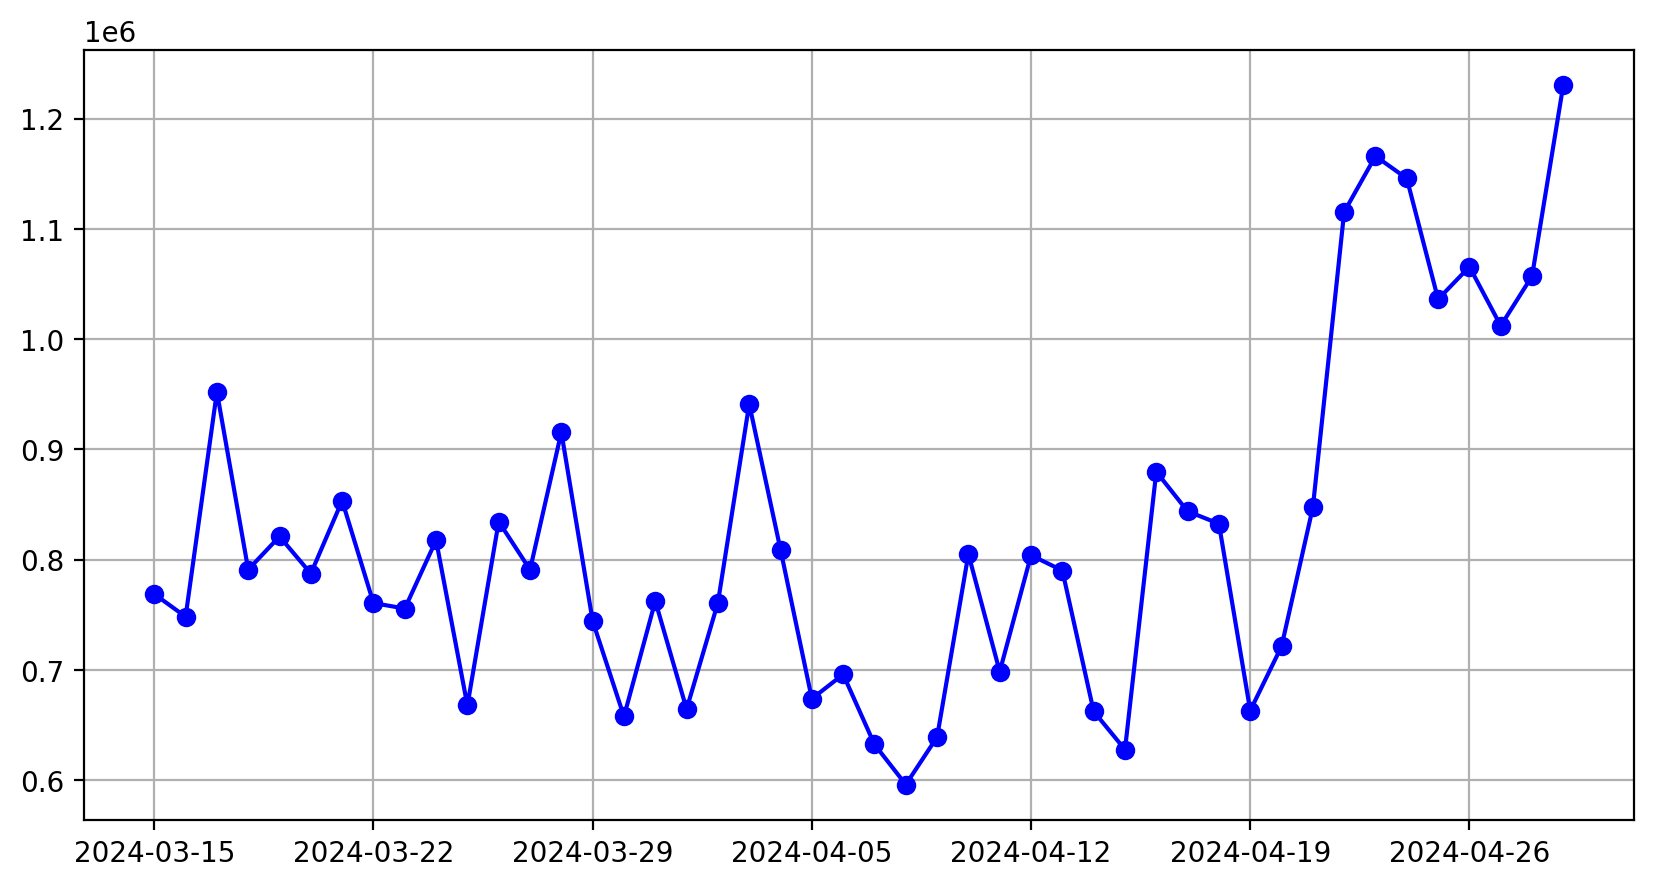

In [55]:
plt.figure(figsize=(10, 5), dpi=200)
plt.plot(pd.DatetimeIndex(df_merged.columns)[46:], daily_all_ping_counts[46:], 'bo-')
plt.xticks(pd.DatetimeIndex(df_merged.columns)[46::7])
plt.grid()

In [56]:
all_dates = pd.DatetimeIndex(df_merged.columns)
sat_ids = np.where((all_dates.dayofweek == 5) & (all_dates.year == 2024))[0][:-2]
sat_datetimes = all_dates[sat_ids]
sat_dates = sat_datetimes.strftime("%Y-%m-%d")


In [23]:
sat_dates

Index(['2024-03-16', '2024-03-23', '2024-03-30', '2024-04-06', '2024-04-13'], dtype='object')

Identify users that have at least a certain number of pings on at least a certain number of days in the base and AR periods

In [57]:
user_count_dict = {}
ar_count_dict = {}
count_vals = [1, 5, 10]
ar_days = [61]
ar_period_days = [60, 61, 62, 63]
baseline_days = (np.arange(0, 92) >= 46) & ~np.isin(np.arange(0, 92), ar_period_days)
counts = df_merged.values
for count in count_vals:
    user_count_dict[count] = np.count_nonzero(counts[:, sat_ids] >= count, axis=1)
    ar_count_dict[count] = np.count_nonzero(counts[:, ar_days] >= count, axis=1)

In [58]:
filtered_users = df_merged.index[(user_count_dict[5] >= 6) & (ar_count_dict[5] == 1)]
home_loc_df.loc[filtered_users].groupby("county").count()["duration"]
user_home_meta = home_loc_df.loc[filtered_users]

In [59]:
zip_counts = home_loc_df.loc[filtered_users].groupby("zipcode").count()["duration"]

In [60]:
with open("/glade/work/cbecker/california_zip.geojson") as cal_zip_file:
    cal_zips = json.load(cal_zip_file)
zip_codes = np.array([cz["properties"]["ZIP_CODE"] for cz in cal_zips["features"]])
zip_index = np.array([int(np.where(zip == zip_codes)[0][0]) for zip in zip_counts.index])

In [61]:
req = urllib3.request("GET", "https://mesonet.agron.iastate.edu/api/1/cow.json?wfo=LOX&begints=2024-03-28T12:00:00Z&enable_shared_border=1&endts=2024-03-31T12:00:00Z&hailsize=1&wind=58&phenomena=FF&lsrbuffer=15&warningbuffer=1")
ffws = json.loads(req.data)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


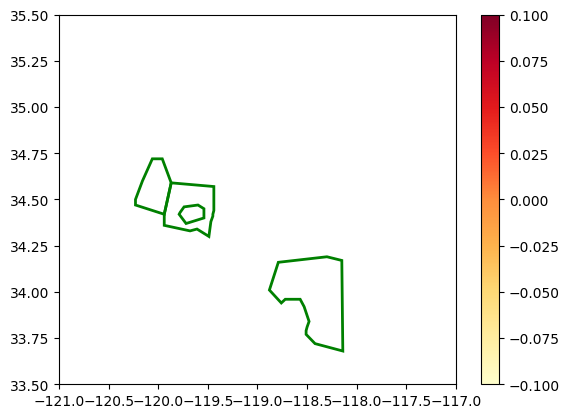

In [62]:

cmap = plt.get_cmap("YlOrRd")
norm = Normalize(0, zip_counts.max())
sm = ScalarMappable(norm=norm, cmap=cmap)
for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_counts.iloc[i]), ec='k', lw=0.5)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none",lw=2)
#for county in county_shapes:
#    county_points = np.array(county.points).T
#    plt.fill(county_points[0], county_points[1], facecolor="none", edgecolor="k", linestyle="--", linewidth=2)
plt.xlim(-121, -117)
plt.ylim(33.5, 35.5)
plt.colorbar(sm, ax=plt.gca())

Filter home locations down to the users that meet the ping count.

# Load and Aggregate Metrics

In [29]:
# Old approach DO NOT USE!

ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_files = list(np.array(ar_files)[sat_ids])
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
df_0 = pd.read_parquet(ar_file, columns=["uid", metric])
df_0 = df_0.set_index("uid")
df_joined = user_home_meta.join(df_0)
new_col = f"{metric}_{ar_date}"
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=["uid", metric])
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l)
    new_col = f"{metric}_{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{metric}_{ar_date}"})
    metric_cols.append(new_col)


NameError: name 'user_home_meta' is not defined

In [67]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_files = list(np.array(ar_files)[sat_ids])
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
df_0 = pd.read_parquet(ar_file, columns=["uid", metric])
df_0 = df_0.set_index("uid")
df_joined = df_0
#df_joined = user_home_meta.join(df_0)
new_col = f"{metric}_{ar_date}"
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=["uid", metric])
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l, how="outer")
    new_col = f"{metric}_{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{metric}_{ar_date}"})
    metric_cols.append(new_col)


100%|██████████| 4/4 [00:17<00:00,  4.30s/it]


In [68]:
df_joined.dropna().sha

(1882357, 5)

In [64]:
df_joined = df_joined.dropna().join(home_loc_df)

In [147]:
m_date = "2024-03-30"
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
daily_ar_data_sub = daily_ar_data.loc[df_joined.index]

In [65]:
df_joined.shape

(83503, 11)

In [148]:
daily_ar_data_sub.shape

(83503, 18)

/glade/derecho/scratch/dgagne/tmp/ipykernel_7609/2763207443.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.pcolormesh(np.log10(df_joined[metric_cols].values))


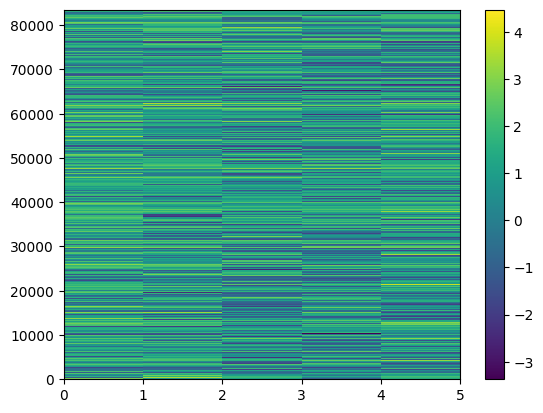

In [128]:
plt.pcolormesh(np.log10(df_joined[metric_cols].values))
plt.colorbar()

In [66]:
ar_files

[np.str_('/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-03-16_PST_chunked.parquet'),
 np.str_('/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-03-23_PST_chunked.parquet'),
 np.str_('/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-03-30_PST_chunked.parquet'),
 np.str_('/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-04-06_PST_chunked.parquet'),
 np.str_('/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-04-13_PST_chunked.parquet')]

In [67]:
met

array([  1.62245547,          nan,  18.41406318,  83.96268741,
       102.02955429])

In [136]:

metric_array = df_joined[metric_cols].values.astype(np.float64)
user_ar_percentile = np.zeros(df_joined.shape[0])
for i in tqdm(range(metric_array.shape[0])):
    user_ar_percentile[i] = percentileofscore(metric_array[i, [True, True, False, True, True]], 
                                              metric_array[i, 2], kind="weak", nan_policy="omit")

100%|██████████| 83503/83503 [00:02<00:00, 35846.77it/s]


In [130]:
metric_array[10]

array([5.91277599e+01, 1.12037791e+01, 8.05152750e-03, 1.12467366e+01,
       4.33055335e+01])

(array([23837.,     0., 16528.,     0.,     0., 14183.,     0., 14703.,
            0., 14252.]),
 array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.]),
 <BarContainer object of 10 artists>)

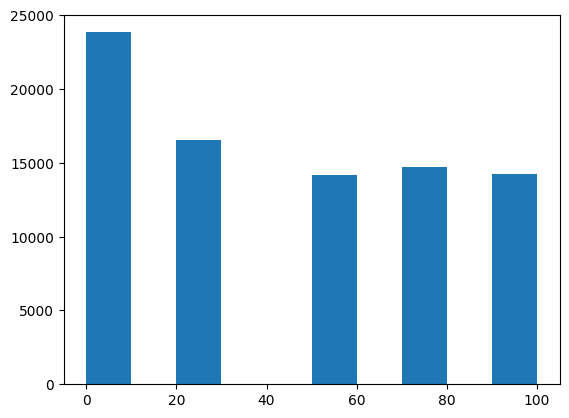

In [137]:
plt.hist(user_ar_percentile)

(array([20724., 19770., 14700., 12729., 15580.]),
 array([0., 1., 2., 3., 4., 5.]),
 <BarContainer object of 5 artists>)

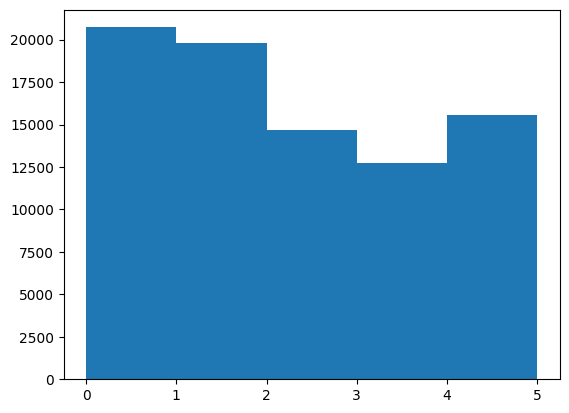

In [138]:
plt.hist(np.argsort(metric_array, axis=1)[:, 3], np.arange(6))

In [57]:
ar_event_dates = ["2024-03-29", "2024-03-30", "2024-03-31", "2024-04-01"]
ar_event_cols = [f"{metric}_{date}" for date in ar_event_dates]
baseline_flag = ~np.isin(metric_cols, ar_event_cols)
baseline_cols = pd.Series(metric_cols)[baseline_flag]
ar_event_flag = np.isin(metric_cols, ar_event_cols)

In [165]:
user_home_meta

,duration,lat,lng,zipcode,row_group,county
uid,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,21 days 11:29:35,34.099681,-117.846496,91724,0,LA
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,41 days 11:56:17,34.105705,-118.328606,90068,4,LA
00052904e43d75374b6b7ce6e7dfd0bf89c70d14f403a6b2bd3ed473621c24b5,5 days 03:49:50,34.263945,-119.219457,93003,6,VE
0005db95f4b81827bbafc84d2c4f20197b6c7af3e7ecd2deb44c70be2b29f92d,13 days 10:11:13,33.983781,-118.201797,90255,6,LA
0005fac987ebae8b8adc1de113207c9da33361abf6b88b909f01f9808690d5d1,14 days 06:35:28,34.276958,-118.413451,91331,6,LA
...,...,...,...,...,...,...
fffe68467d281000b4b4a4d22fabfd43f58683acdd65a7dc9f3d1c94931f2b53,1 days 00:30:13,33.904062,-118.143072,90242,75015,LA
fffea50b3f97f128692ab729cfe29053043805294515ef1299ae645434b8de22,14 days 16:47:30,34.575502,-118.032679,93552,75016,LA
fffeffd69e034688698f5e1537cc707055798167994b71f0d9c29b10e6145d17,9 days 13:45:51,34.272712,-119.184113,93004,75016,VE


In [89]:
base_log_metric = np.log(np.maximum(df_joined[metric_cols], 1e-4))
people_means = np.nanmean(base_log_metric, axis=1)
people_sds  = np.nanstd(base_log_metric, axis=1)
people_ns = np.count_nonzero(~np.isnan(base_log_metric), axis=1)
z_score = (base_log_metric[f"{metric}_2024-03-30"]  - people_means) / (people_sds)
z_score_samp = (base_log_metric[f"{metric}_2024-03-30"]  - people_means) / (people_sds/ np.sqrt(people_ns))

In [169]:
zip_traces = pd.DataFrame(0.0, index=zip_counts.index, columns=["distance_straight_line_2024-03-30"])
for zip_code in zip_counts.index:
    zip_traces.loc[zip_code] = np.mean(user_ar_percentile[df_joined["zipcode"] == zip_code], axis=0)


In [143]:
rain_ds = xr.open_dataset("/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc")
rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").max() / 25.4

<xarray.DataArray 'MultiSensor_QPE_01H_Pass2_00.00_sum' ()> Size: 8B
array(4.93700787)
Coordinates:
    time     datetime64[ns] 8B 2024-03-30
Attributes:
    Discipline:   209
    Category:     6.0
    Parameter:    37.0
    Name:         MultiSensor_QPE_01H_Pass2
    Frequency:    60-min
    Unit:         mm
    Missing:      -1.0
    No Coverage:  -3.0
    Description:  Multi-sensor accumulation 1-hour (2-hour latency)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


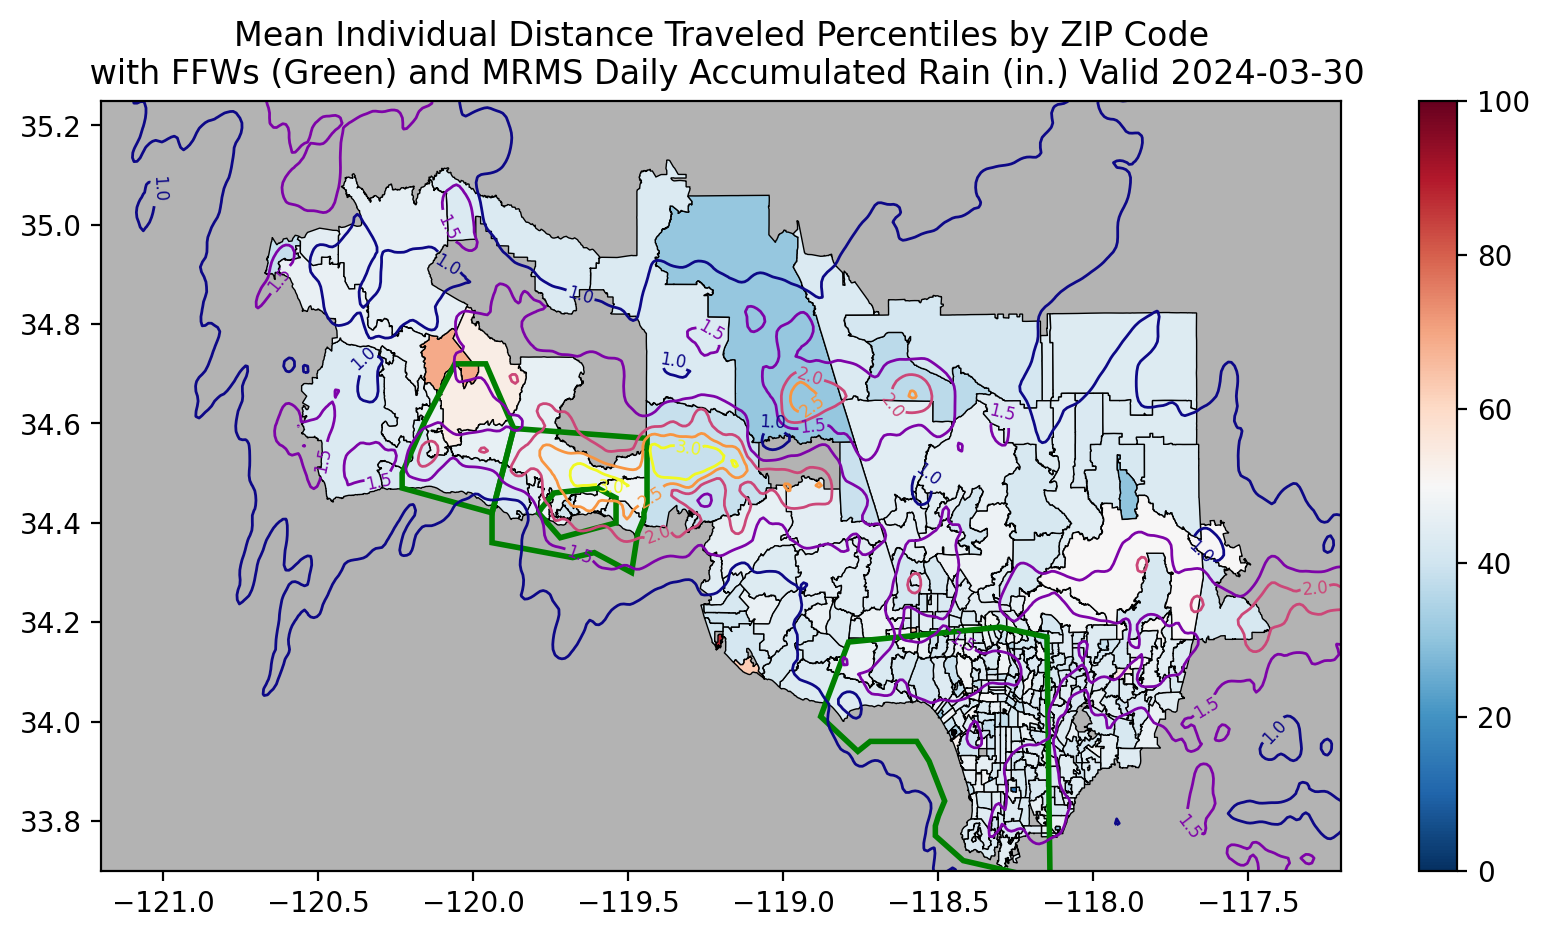

In [173]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r")
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)
for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc["distance_straight_line_2024-03-30"]), ec='k', lw=0.5)
plt.xlim(-121.2, -117.2)
plt.ylim(33.7, 35.25)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


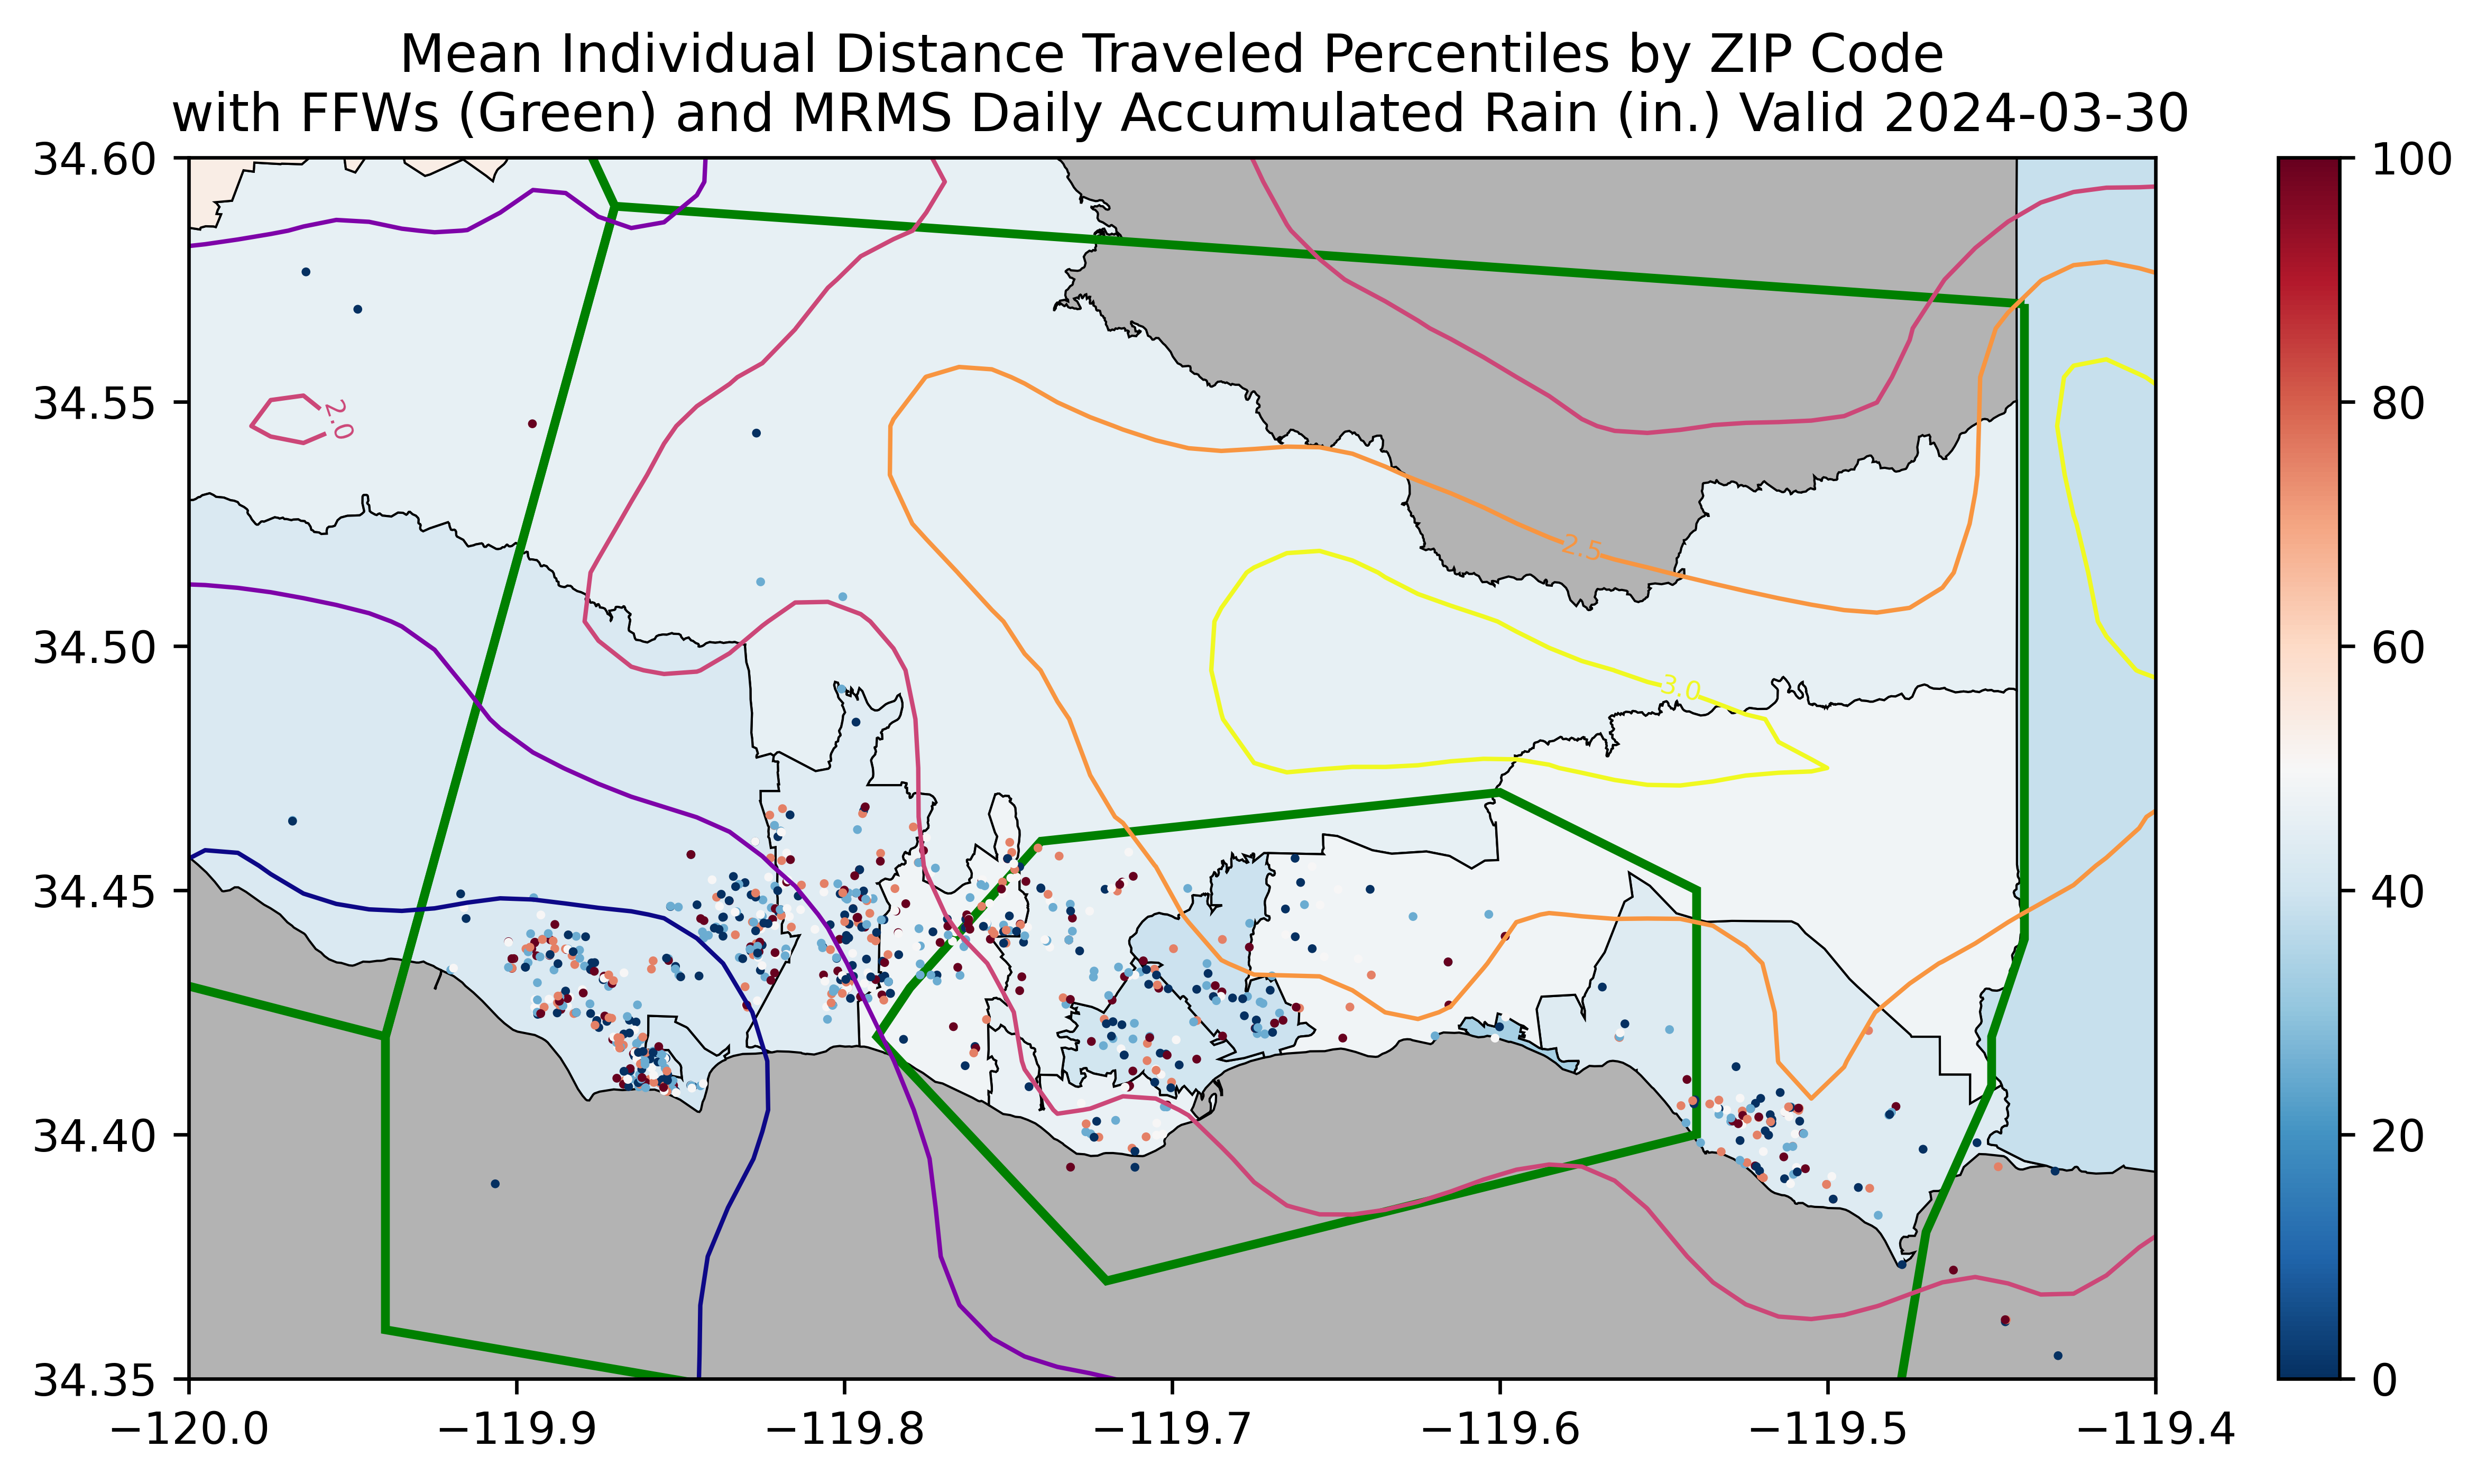

In [171]:
fig = plt.figure(figsize=(10, 5), dpi=600)
cmap = plt.get_cmap("RdBu_r")
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)
for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc["distance_straight_line_2024-03-30"]), ec='k', lw=0.5)
plt.xlim(-120.0, -119.4)
plt.ylim(34.35, 34.6)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.scatter(daily_ar_data_sub["lng_home"], daily_ar_data_sub["lat_home"], 1, user_ar_percentile, cmap=cmap, vmin=0, vmax=100)
plt.clabel(rain_cont, fontsize=6)
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_inset.png", bbox_inches="tight", dpi=600)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


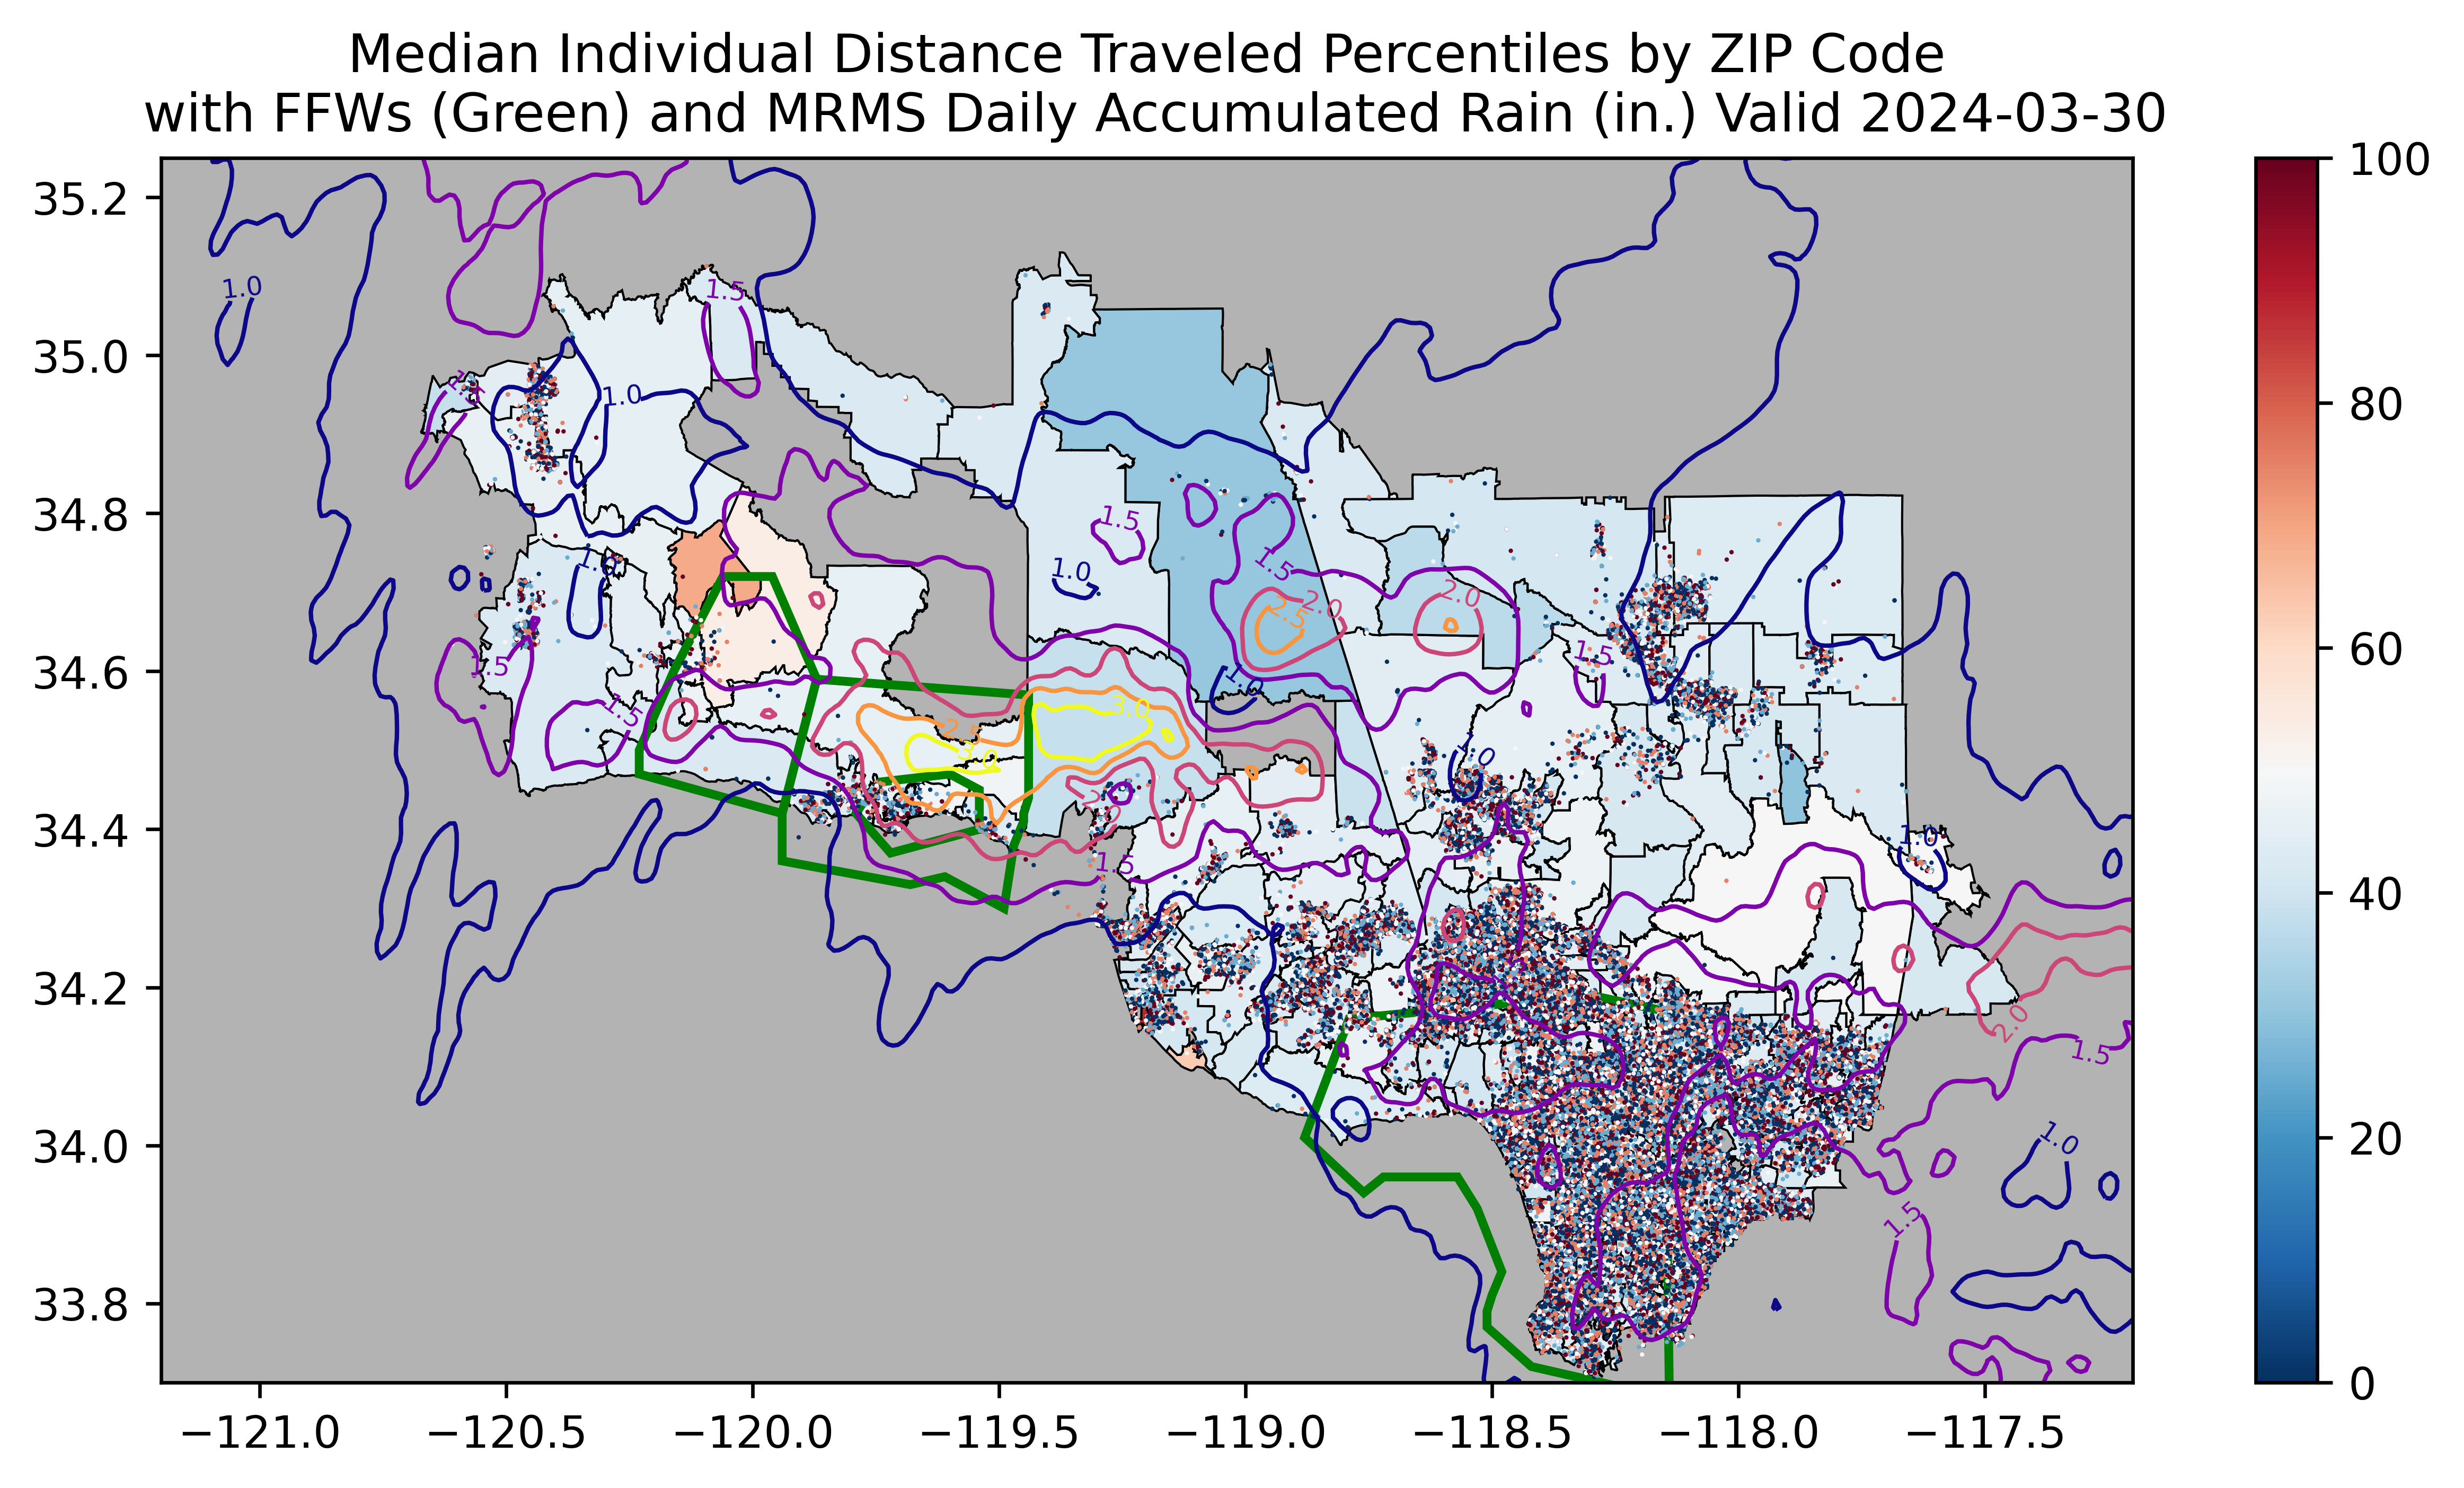

In [177]:
fig = plt.figure(figsize=(10, 5), dpi=600)
cmap = plt.get_cmap("RdBu_r")
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)
for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc["distance_straight_line_2024-03-30"]), ec='k', lw=0.5)
plt.xlim(-121.2, -117.2)
plt.ylim(33.7, 35.25)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.scatter(daily_ar_data_sub["lng_home"], daily_ar_data_sub["lat_home"], 1, user_ar_percentile, cmap=cmap, vmin=0, vmax=100, ec="none")
plt.clabel(rain_cont, fontsize=6)
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Median Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_dots.png", bbox_inches="tight", dpi=600)

In [149]:
rain_match_points = rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").sel(lon=xr.DataArray(daily_ar_data_sub["lng_home"].values + 360, dims="points"), 
                                                                          lat=xr.DataArray(daily_ar_data_sub["lat_home"].values , dims="points"), method="nearest")

(array([3.1400e+02, 3.2350e+03, 5.5550e+03, 1.8790e+04, 4.0482e+04,
        1.1070e+04, 3.4900e+03, 3.3600e+02, 1.9500e+02, 3.6000e+01]),
 array([10.2 , 16.18, 22.16, 28.14, 34.12, 40.1 , 46.08, 52.06, 58.04,
        64.02, 70.  ]),
 [<matplotlib.patches.Polygon at 0x149d2da50a90>])

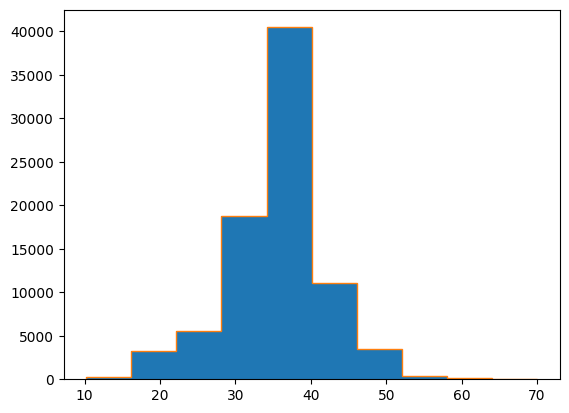

In [150]:
plt.hist(rain_match_points.values)
plt.hist(daily_ar_data_sub["precip_sum"], histtype="step")

In [151]:
daily_ar_data_sub["distance_traveled_percentile"] = user_ar_percentile

In [181]:
daily_ar_data_sub.index

Index(['000410d2eb6bcdd8e3a21e7d55ba32a556e023e8b70915b916eb6dd8e5c9dd21',
       '00052904e43d75374b6b7ce6e7dfd0bf89c70d14f403a6b2bd3ed473621c24b5',
       '0005db95f4b81827bbafc84d2c4f20197b6c7af3e7ecd2deb44c70be2b29f92d',
       '0005fac987ebae8b8adc1de113207c9da33361abf6b88b909f01f9808690d5d1',
       '00065ed65abecbf863abdd49ec8e87100128c416509dca2f8b4aa544ba108cf0',
       '0007231af91da10ead42a18874321bd237187a2645a973197720cfedeea9f061',
       '00078c39be3e1b3efbfaa838b95d8021e068cb9a4b0aaae1e181a354630e659b',
       '0008fbf0608355636669c10680a4c0721c134eba88e7ad9b290ad44c6c1d5a19',
       '00097c0879e9bbb406e02a050e8193f4fe5655be5ad3f4916cb41703f8ce4c1d',
       '000c4913eb7ef6b404d026cf6d3ffa626e44ebbe3441075088e54dd6cb968c19',
       ...
       'fff969661bbac4e5784acf140b341df8411c25124e2d65694dce0d9b8df12e41',
       'fffaf8412e08912fec99ee46ded8f2c0d9fdc10281c1d82ddaf5fcbbca8d12ea',
       'fffb7b42174d283e20343772733c9f13e7bea913cc285d5b91346075aa50b5b2',
       'fffda4

In [182]:
df_joined.index

Index(['000410d2eb6bcdd8e3a21e7d55ba32a556e023e8b70915b916eb6dd8e5c9dd21',
       '00052904e43d75374b6b7ce6e7dfd0bf89c70d14f403a6b2bd3ed473621c24b5',
       '0005db95f4b81827bbafc84d2c4f20197b6c7af3e7ecd2deb44c70be2b29f92d',
       '0005fac987ebae8b8adc1de113207c9da33361abf6b88b909f01f9808690d5d1',
       '00065ed65abecbf863abdd49ec8e87100128c416509dca2f8b4aa544ba108cf0',
       '0007231af91da10ead42a18874321bd237187a2645a973197720cfedeea9f061',
       '00078c39be3e1b3efbfaa838b95d8021e068cb9a4b0aaae1e181a354630e659b',
       '0008fbf0608355636669c10680a4c0721c134eba88e7ad9b290ad44c6c1d5a19',
       '00097c0879e9bbb406e02a050e8193f4fe5655be5ad3f4916cb41703f8ce4c1d',
       '000c4913eb7ef6b404d026cf6d3ffa626e44ebbe3441075088e54dd6cb968c19',
       ...
       'fff969661bbac4e5784acf140b341df8411c25124e2d65694dce0d9b8df12e41',
       'fffaf8412e08912fec99ee46ded8f2c0d9fdc10281c1d82ddaf5fcbbca8d12ea',
       'fffb7b42174d283e20343772733c9f13e7bea913cc285d5b91346075aa50b5b2',
       'fffda4

In [152]:
daily_ar_data_sub.columns

Index(['duration', 'lat_home', 'lng_home', 'zipcode', 'row_group', 'county',
       'number_of_visits', 'distance_straight_line', 'jump_lengths',
       'radius_of_gyration', 'num_stops', 'max_distance_from_home', 'date',
       'FFW', 'precip_max', 'precip_sum', 'streamflow_max', 'streamflow_sum',
       'distance_traveled_percentile'],
      dtype='object')

In [153]:
daily_ar_data_sub["streamflow_sum"].max()

np.float64(23.9)

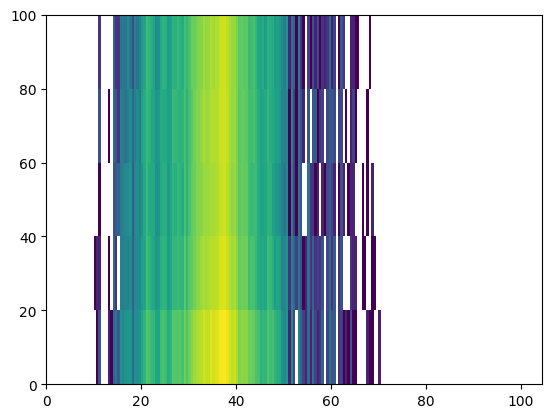

In [184]:
_ = plt.hist2d(daily_ar_data_sub["precip_sum"], 
               daily_ar_data_sub["distance_traveled_percentile"], bins=[np.arange(0, 105, 0.5), 
                                                                        np.arange(0, 105, 20)], cmin=1, norm=LogNorm(), density=False)

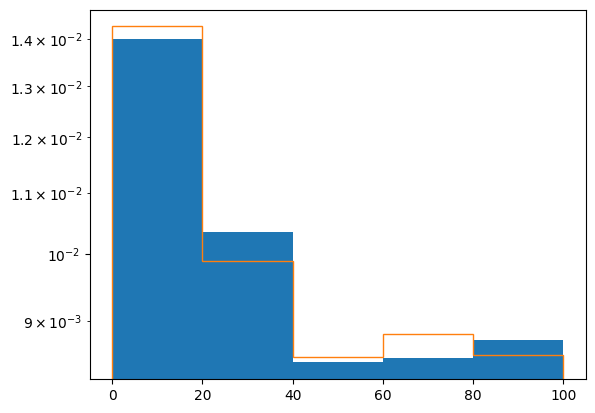

In [217]:
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["streamflow_sum"] >= 15], np.arange(0, 120, 20), density=True)
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["streamflow_sum"] < 15], np.arange(0, 120, 20), density=True, 
         histtype="step")
plt.gca().set_yscale("log")

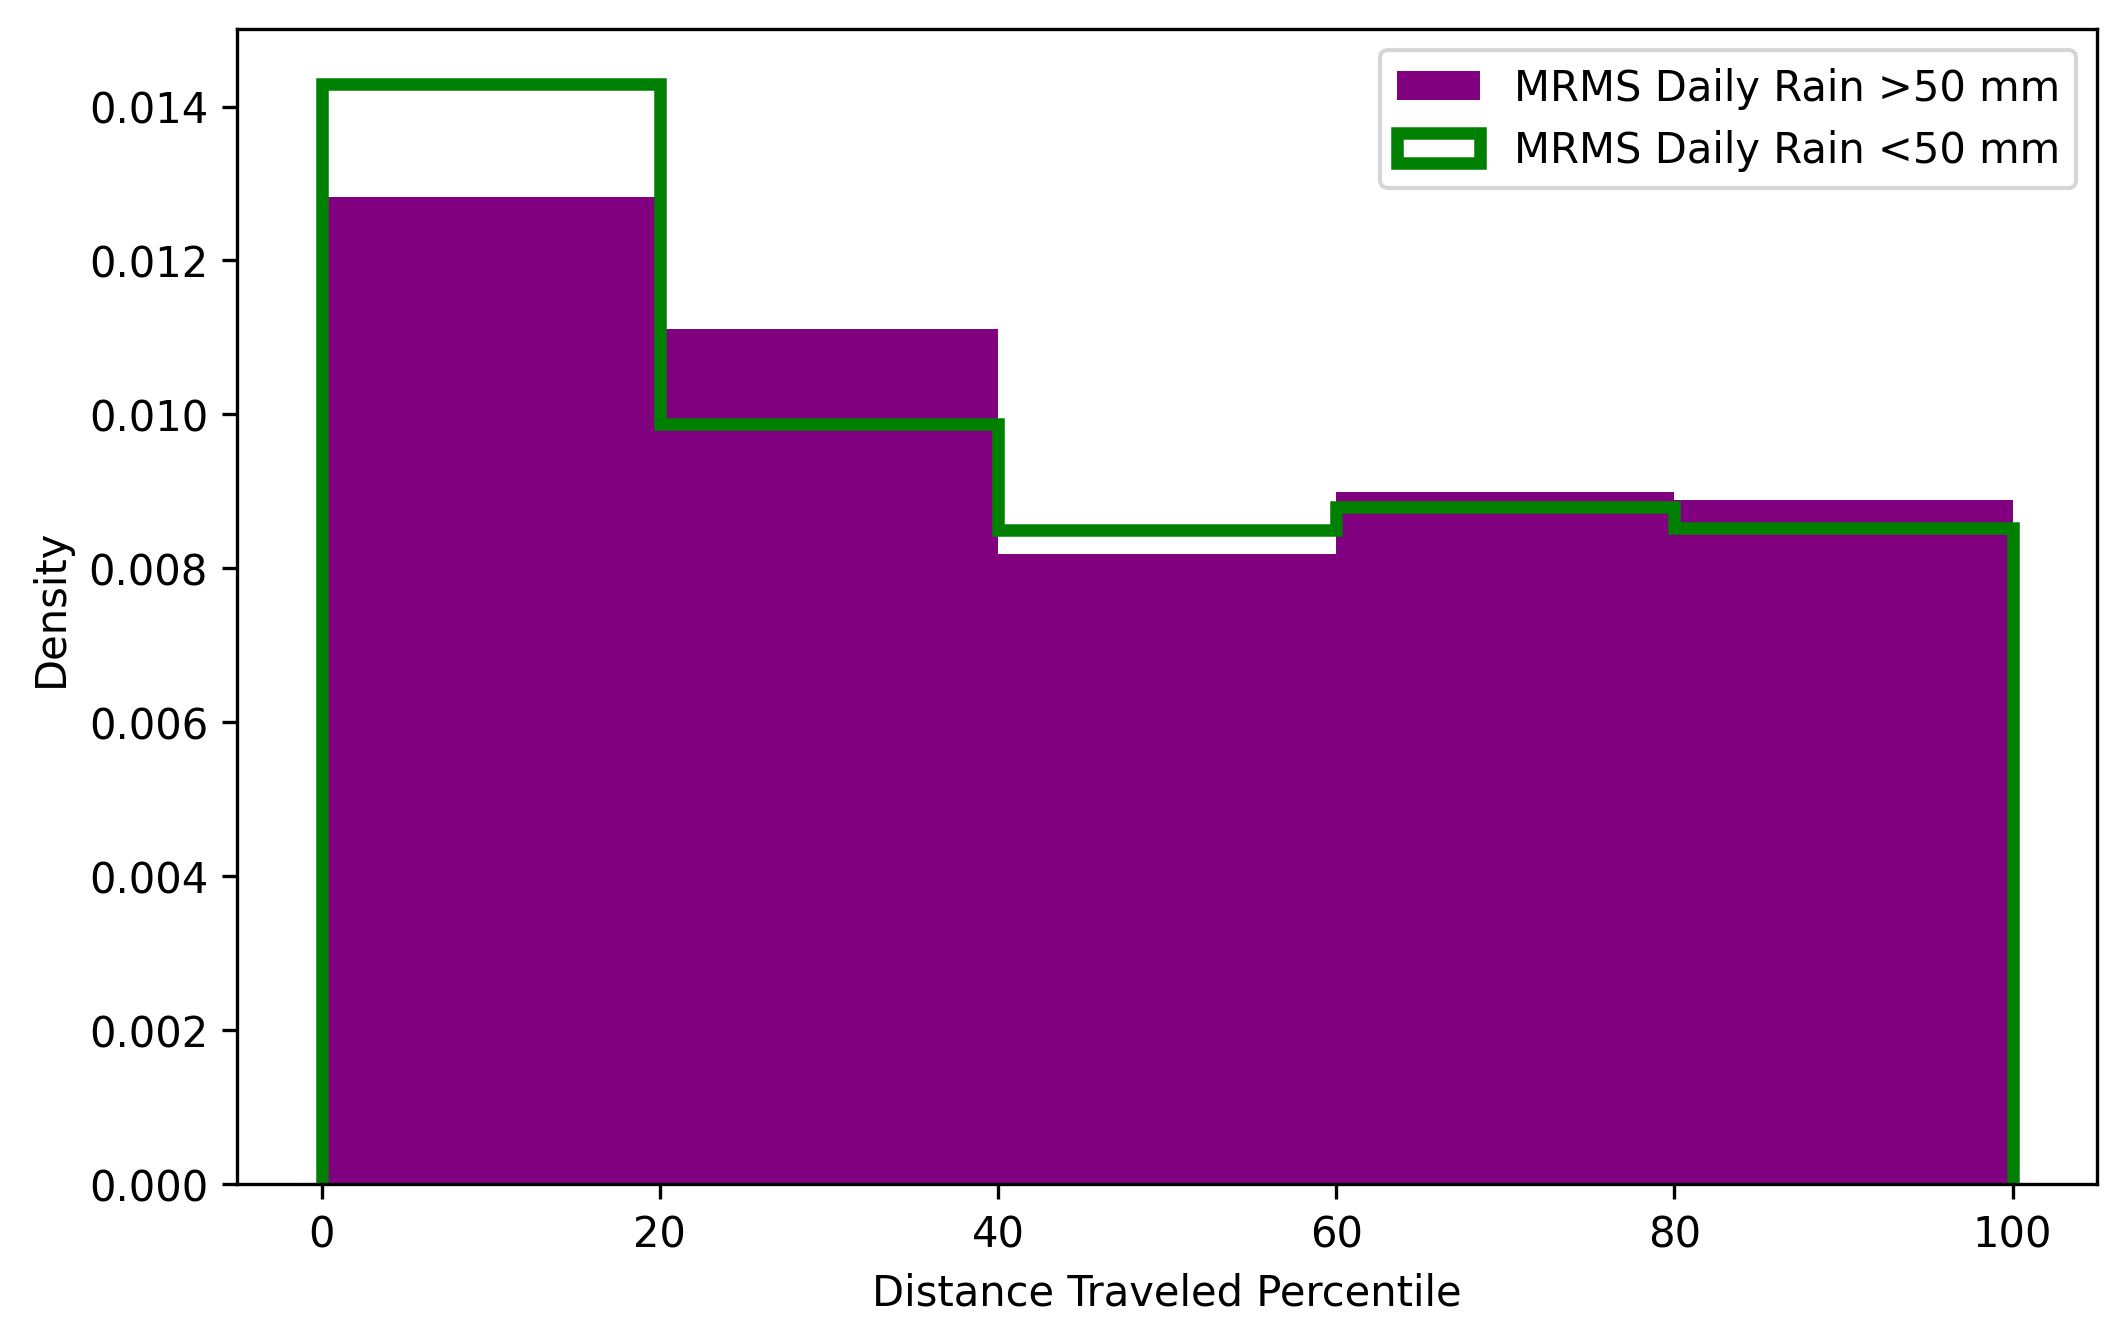

In [237]:
plt.figure(figsize=(8, 5), dpi=300)
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["precip_sum"] >= 50], np.arange(0, 120, 20), density=True, color="purple", 
         label="MRMS Daily Rain >50 mm")
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["precip_sum"] < 50], np.arange(0, 120, 20), density=True, color="green", linewidth=3,
         histtype="step", label="MRMS Daily Rain <50 mm")
plt.legend()
plt.xlabel("Distance Traveled Percentile")
plt.ylabel("Density")
plt.savefig("mrms_precip_hist.png", dpi=300, bbox_inches="tight")

<Axes: >

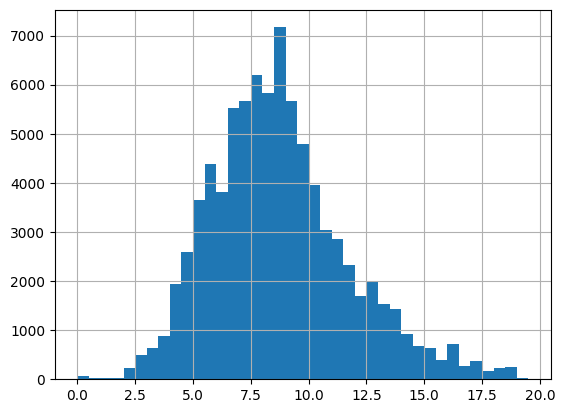

In [207]:
daily_ar_data_sub["streamflow_sum"].hist(bins=np.arange(0, 20, 0.5))

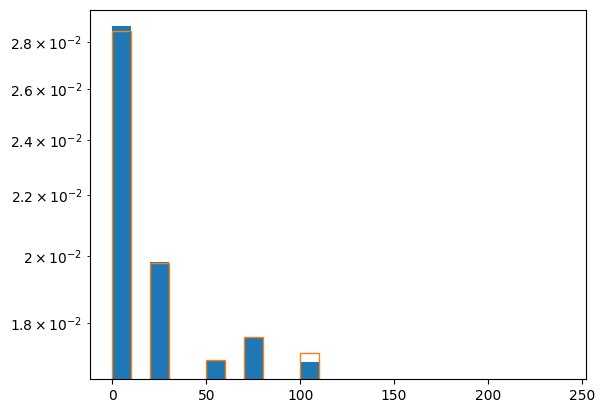

In [188]:
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["FFW"]], np.arange(0, 250, 10), density=True)
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][~daily_ar_data_sub["FFW"]], np.arange(0, 250, 10), density=True, 
         histtype="step")
plt.gca().set_yscale("log")

In [253]:
daily_ar_data_sub.columns

Index(['duration', 'lat_home', 'lng_home', 'zipcode', 'row_group', 'county',
       'number_of_visits', 'distance_straight_line', 'jump_lengths',
       'radius_of_gyration', 'num_stops', 'max_distance_from_home', 'date',
       'FFW', 'precip_max', 'precip_sum', 'streamflow_max', 'streamflow_sum',
       'distance_traveled_percentile'],
      dtype='object')

(array([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.3000e+01,
        7.7000e+01, 1.9300e+02, 1.6440e+03, 3.3910e+03, 6.5850e+03,
        1.0191e+04, 1.0518e+04, 1.1682e+04, 1.0738e+04, 6.8770e+03,
        5.7030e+03, 3.8620e+03, 2.9700e+03, 2.3320e+03, 1.7110e+03,
        1.4980e+03, 1.2830e+03, 6.7000e+02, 5.6500e+02, 5.6100e+02,
        1.8500e+02, 7.8000e+01, 5.9000e+01, 2.3000e+01, 3.2000e+01,
        3.0000e+00, 1.5000e+01, 1.8000e+01, 1.6000e+01, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00]),
 array([ 0. ,  0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,
         5.5,  6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. , 10.5,
        11. , 11.5, 12. , 12.5, 13. , 13.5, 14. , 14.5, 15. , 15.5, 16. ,
        16.5, 17. , 17.5, 18. , 18.5, 19. , 19.5, 20. , 20.5, 21. , 21.5,
        22. , 22.5, 23. , 23.5, 24

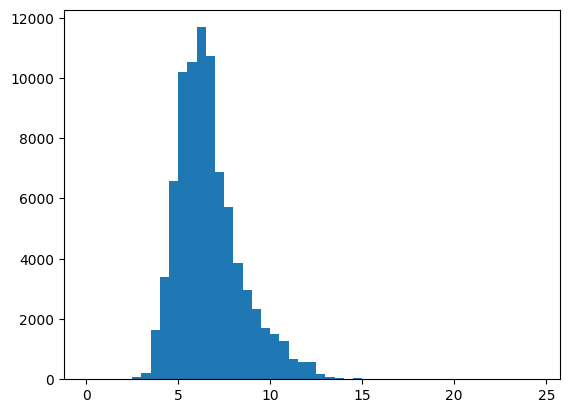

In [192]:
plt.hist(daily_ar_data_sub["precip_max"], np.arange(0, 25, 0.5))

(array([0.05693024, 0.        , 0.        , 0.        , 0.        ,
        0.0395535 , 0.        , 0.        , 0.        , 0.        ,
        0.03398983, 0.        , 0.        , 0.        , 0.        ,
        0.03520153, 0.        , 0.        , 0.        , 0.0343249 ]),
 array([  0.,   5.,  10.,  15.,  20.,  25.,  30.,  35.,  40.,  45.,  50.,
         55.,  60.,  65.,  70.,  75.,  80.,  85.,  90.,  95., 100.]),
 [<matplotlib.patches.Polygon at 0x149ffe283f10>])

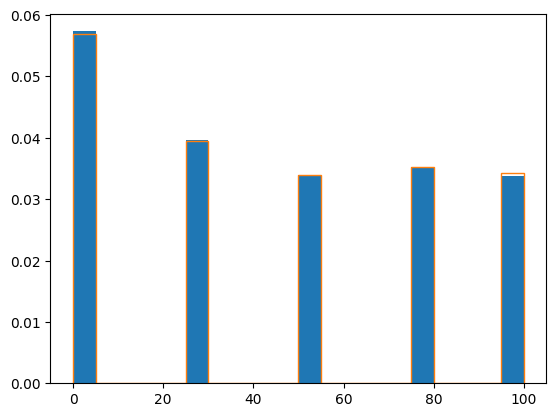

In [179]:
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][daily_ar_data_sub["FFW"]], np.arange(0, 105, 5), density=True, cumulative=False)
plt.hist(daily_ar_data_sub["distance_traveled_percentile"][~daily_ar_data_sub["FFW"]], np.arange(0, 105, 5), density=True, 
         histtype="step", cumulative=False)

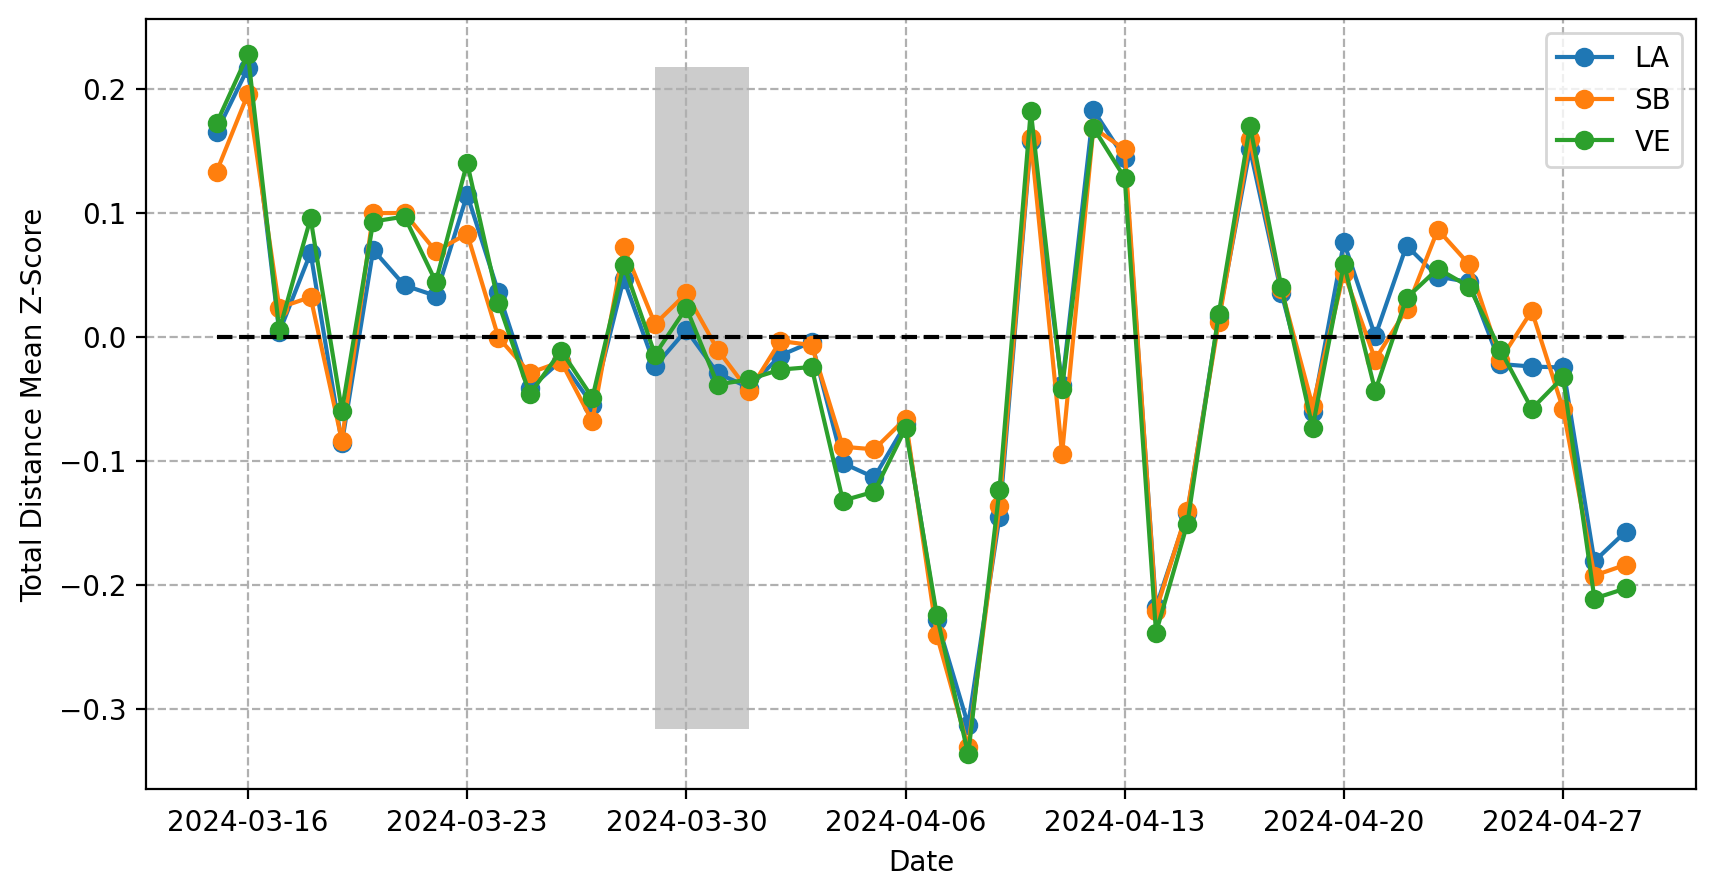

In [85]:
dates = [x.split("_")[-1] for x in metric_cols]
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces = []
for county in counties:
    traces.append(np.nanmean(z_score_base.loc[user_home_meta["county"] == county], axis=0))
d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces):
    plt.plot(d_idx, trace, marker='o', label=counties[t])
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()
plt.savefig("mean_dist_z_score.png", bbox_inches="tight")

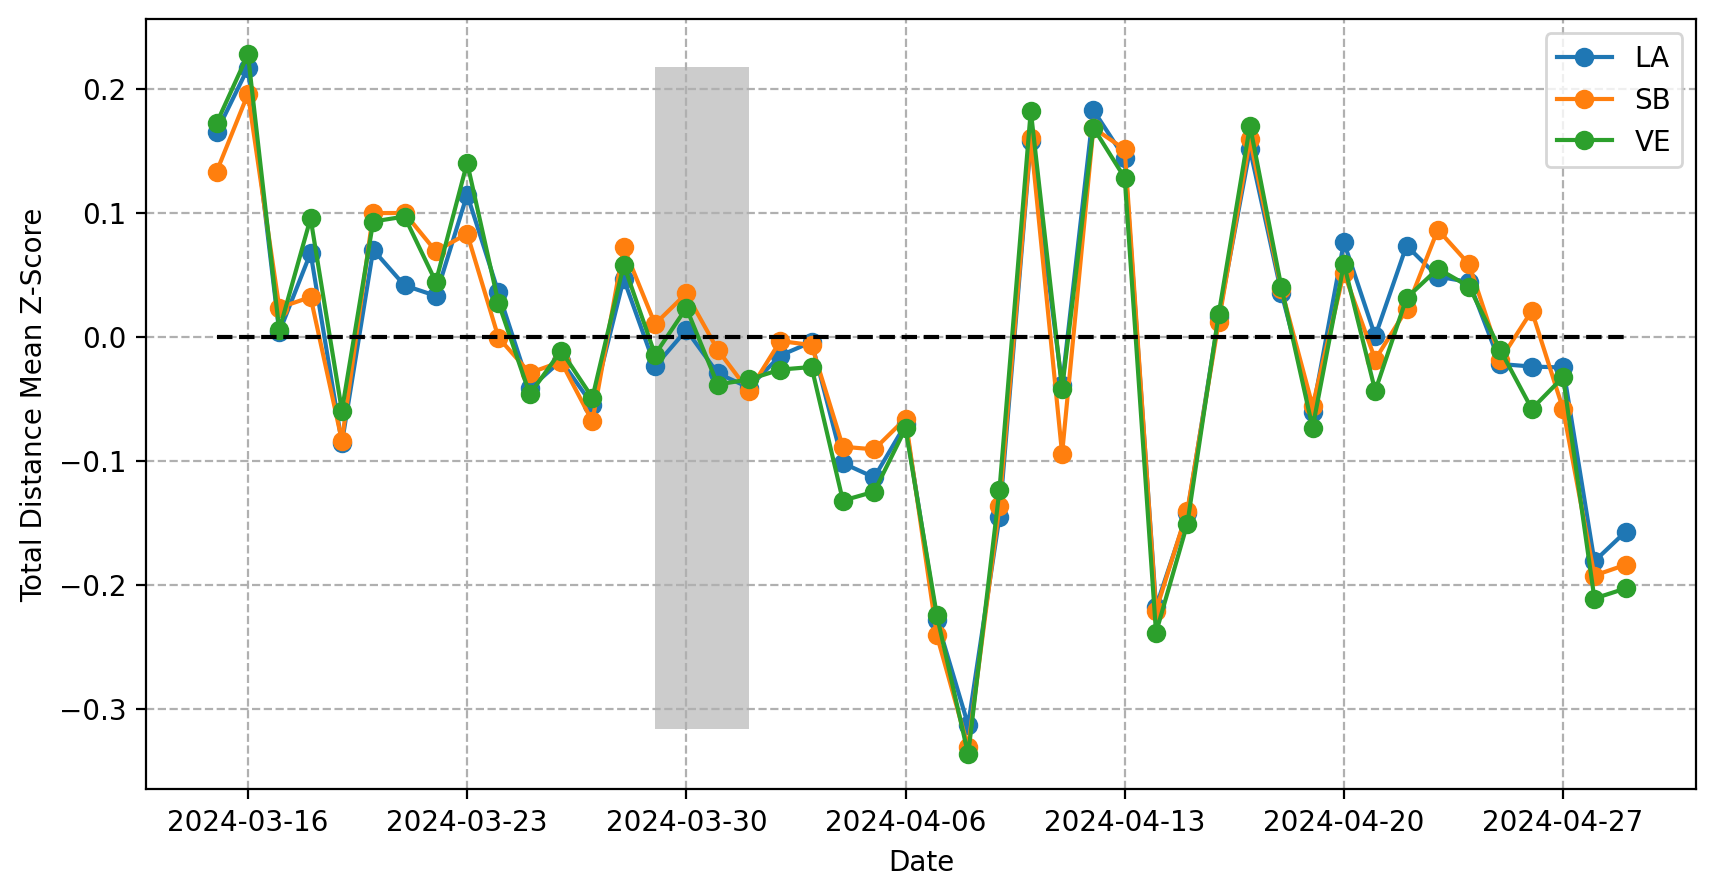

In [109]:
dates = [x.split("_")[-1] for x in metric_cols]
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces = []
for county in counties:
    traces.append(np.nanmean(z_score_base.loc[user_home_meta["county"] == county], axis=0))
d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces):
    plt.plot(d_idx, trace, marker='o', label=counties[t])
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()
plt.savefig("mean_dist_z_score.png", bbox_inches="tight")

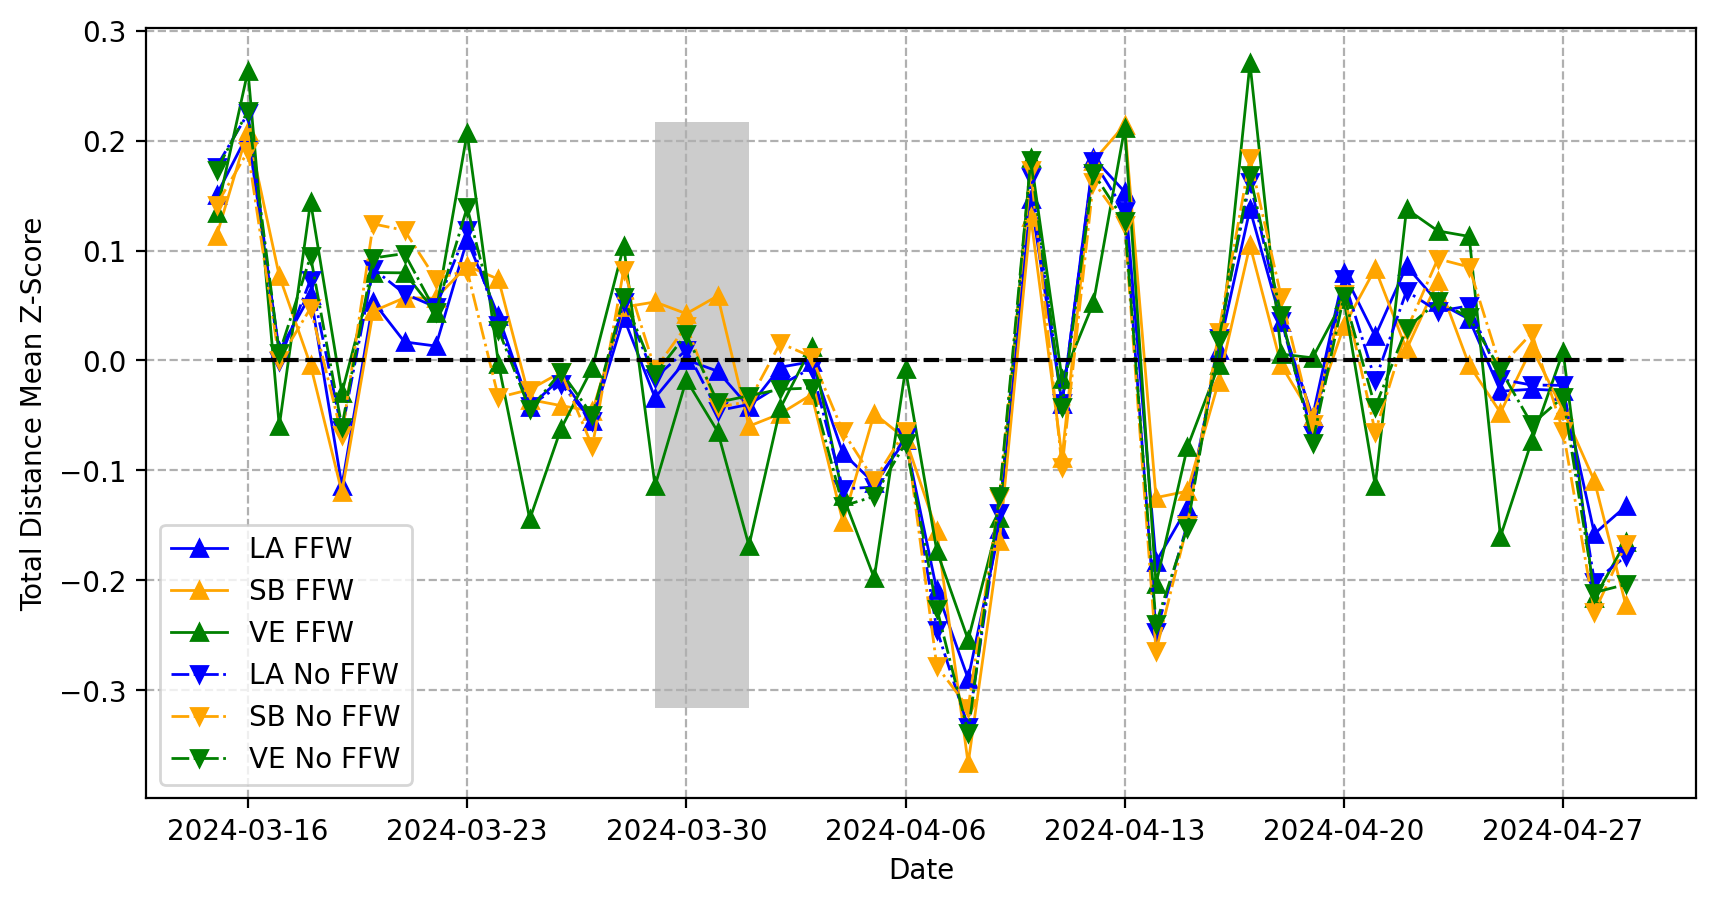

In [110]:
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces_pos = []
traces_neg = []
colors = ['blue', 'orange', 'green']
pos_ls = '-'
neg_ls = '-.'
pos_mark = '^'
neg_mark = 'v'
for county in counties:
    traces_pos.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & daily_ar_data_sub["FFW"]], axis=0))
    traces_neg.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & ~daily_ar_data_sub["FFW"]], axis=0))

d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces_pos):
    plt.plot(d_idx, trace, marker=pos_mark, color=colors[t], ls=pos_ls, label=counties[t] + " FFW", lw=1)
for t, trace in enumerate(traces_neg):
    plt.plot(d_idx, trace, marker=neg_mark, color=colors[t], ls=neg_ls, label=counties[t] + " No FFW", lw=1)
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()

plt.savefig("mean_dist_z_score_pos_neg.png", bbox_inches="tight")

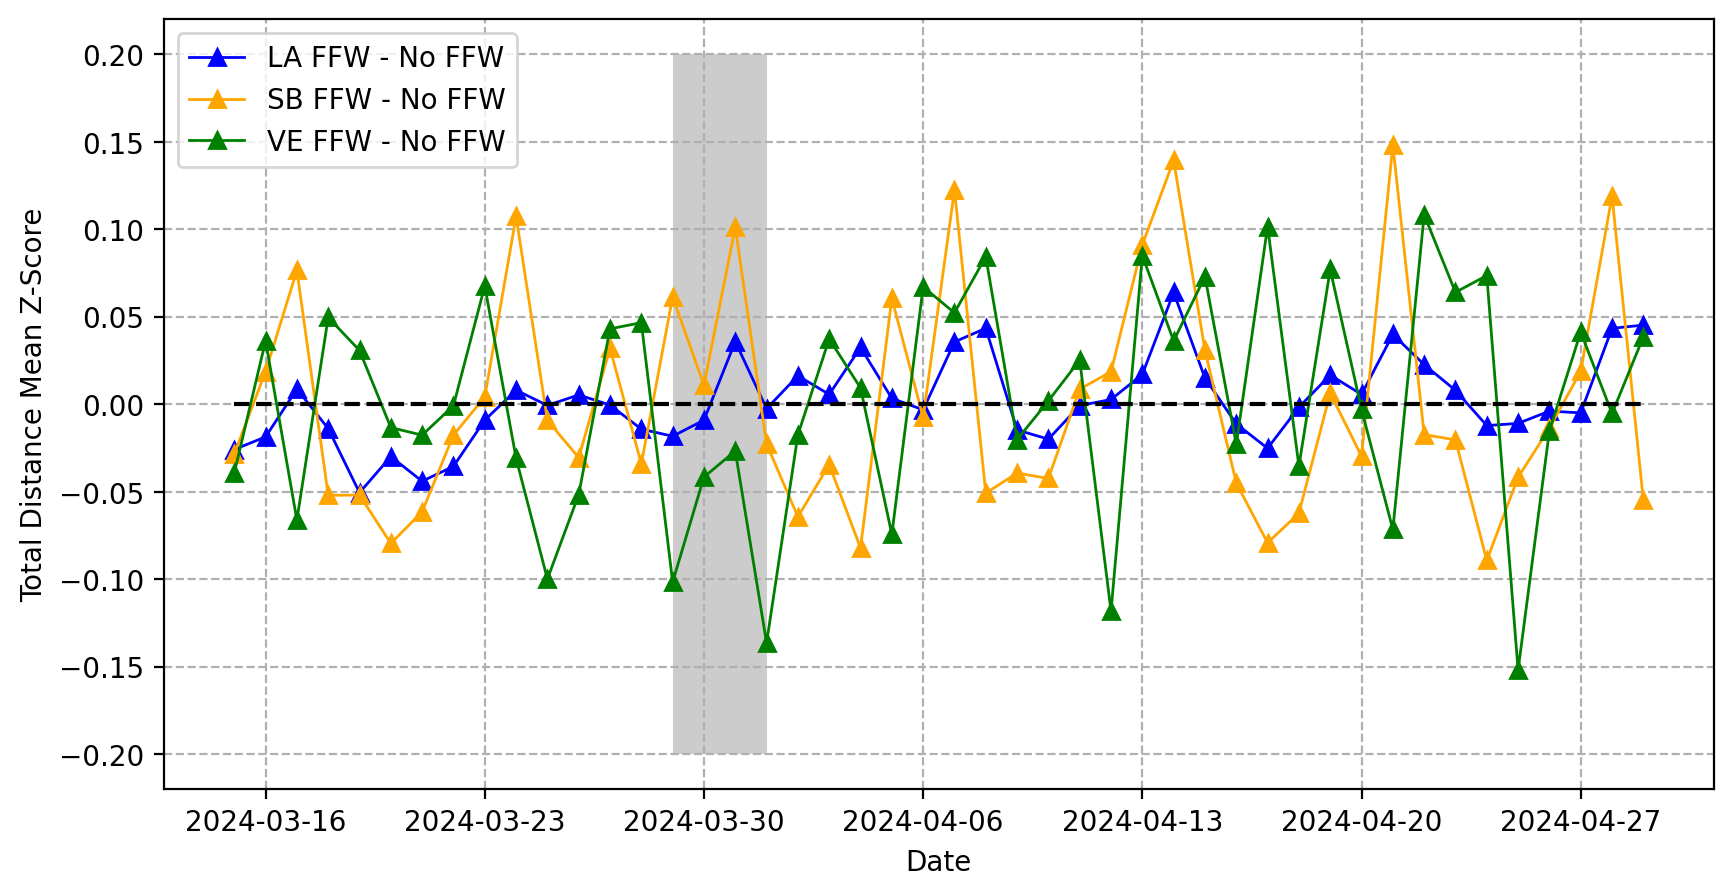

In [91]:
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces_pos = []
traces_neg = []
colors = ['blue', 'orange', 'green']
pos_ls = '-'
neg_ls = '-.'
pos_mark = '^'
neg_mark = 'v'
for county in counties:
    traces_pos.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & daily_ar_data_sub["FFW"]], axis=0))
    traces_neg.append(np.nanmean(z_score_base.loc[(user_home_meta["county"] == county) & ~daily_ar_data_sub["FFW"]], axis=0))

d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), -0.2, 0.2, fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces_pos):
    plt.plot(d_idx, trace - traces_neg[t], marker=pos_mark, color=colors[t], ls=pos_ls, label=counties[t] + " FFW - No FFW", lw=1)
#for t, trace in enumerate(traces_neg):
#    plt.plot(d_idx, trace, marker=neg_mark, color=colors[t], ls=neg_ls, label=counties[t] + " No FFW", lw=1)
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()

plt.savefig("mean_dist_z_score_diff.png", bbox_inches="tight", dpi=300)

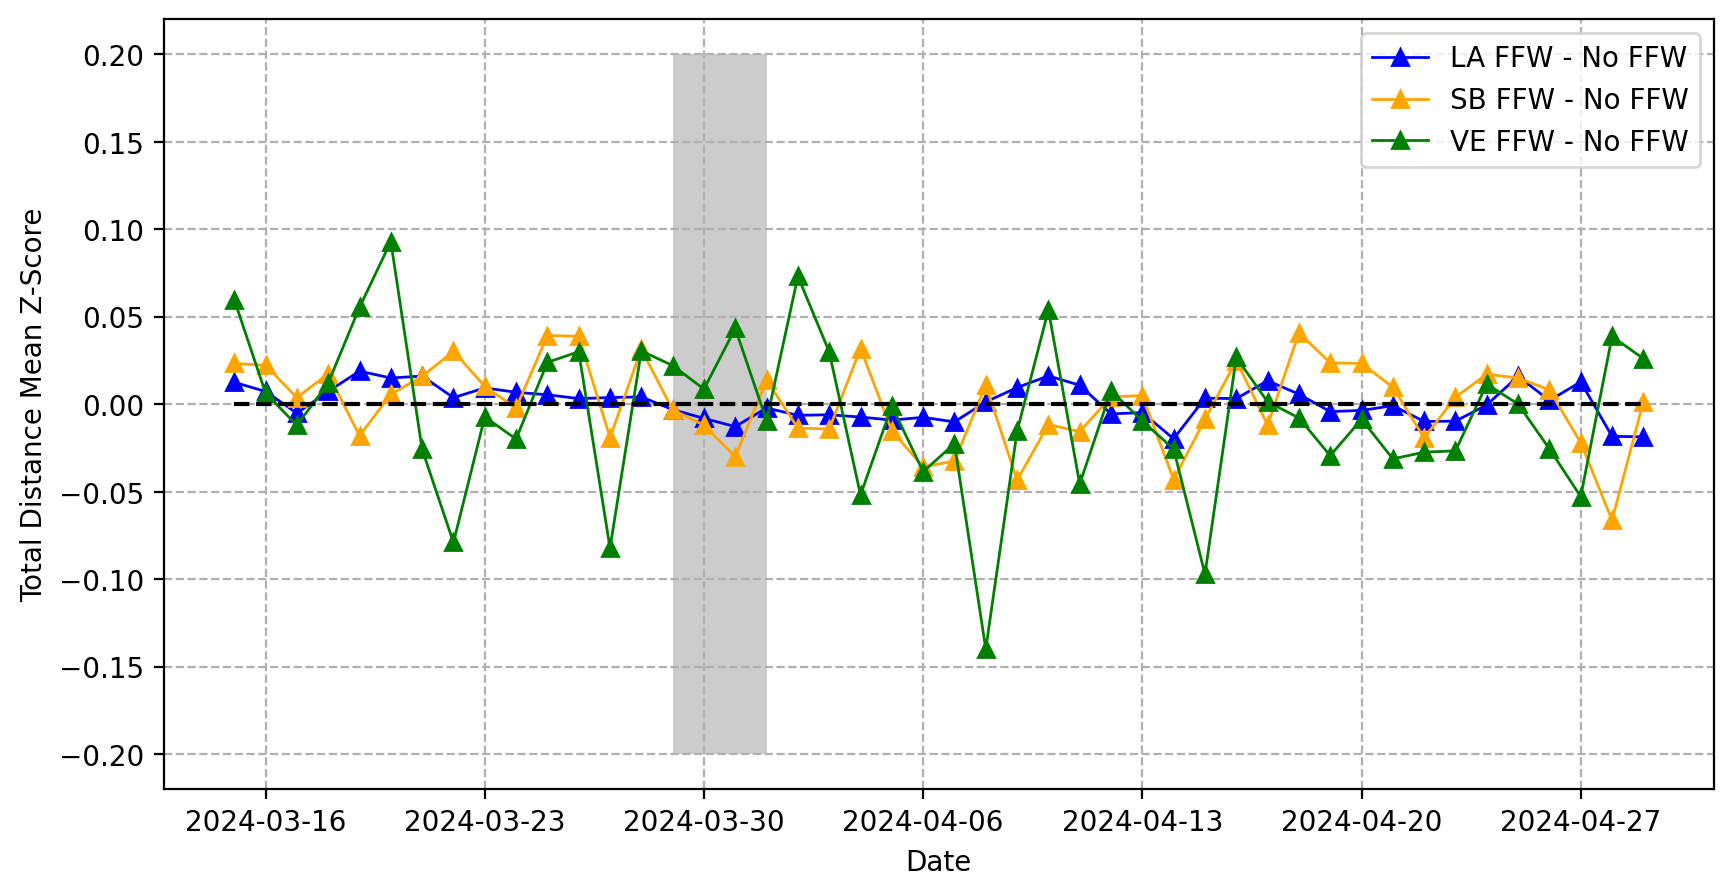

In [95]:
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)
counties = ["LA", "SB", "VE"]
traces_pos_sd = []
traces_neg_sd = []
colors = ['blue', 'orange', 'green']
pos_ls = '-'
neg_ls = '-.'
pos_mark = '^'
neg_mark = 'v'
for county in counties:
    traces_pos_sd.append(np.nanstd(z_score_base.loc[(user_home_meta["county"] == county) & daily_ar_data_sub["FFW"]], axis=0))
    traces_neg_sd.append(np.nanstd(z_score_base.loc[(user_home_meta["county"] == county) & ~daily_ar_data_sub["FFW"]], axis=0))

d_idx = pd.DatetimeIndex(dates)
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), -0.2, 0.2, fc='0.8')
#plt.plot(d_idx, z_trace, marker='.', color='k')
for t, trace in enumerate(traces_pos_sd):
    plt.plot(d_idx, trace - traces_neg_sd[t], marker=pos_mark, color=colors[t], ls=pos_ls, label=counties[t] + " FFW - No FFW", lw=1)
#for t, trace in enumerate(traces_neg):
#    plt.plot(d_idx, trace, marker=neg_mark, color=colors[t], ls=neg_ls, label=counties[t] + " No FFW", lw=1)
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.legend()

plt.savefig("sd_dist_z_score_diff.png", bbox_inches="tight", dpi=300)

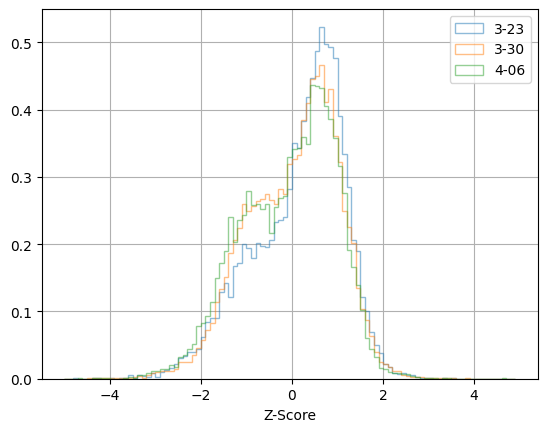

In [111]:
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-03-23"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, cumulative=False, 
                                                                                   label="3-23", alpha=0.5,
                                                                                   histtype='step')
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-03-30"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, cumulative=False, label="3-30", 
                                                                                   alpha=0.5,
                                                                                   histtype='step')
z_score_base.loc[daily_ar_data_sub["county"] == "VE", f"{metric}_2024-04-06"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, 
                                                                                   cumulative=False, label="4-06", alpha=0.5,
                                                                                  histtype='step')

plt.xlabel("Z-Score")
plt.legend()
plt.savefig("day_comp_hist.png", bbox_inches="tight")

In [89]:
uid_counts = np.count_nonzero(~np.isnan(z_score_base), axis=1)
row_align = np.argsort(uid_counts)

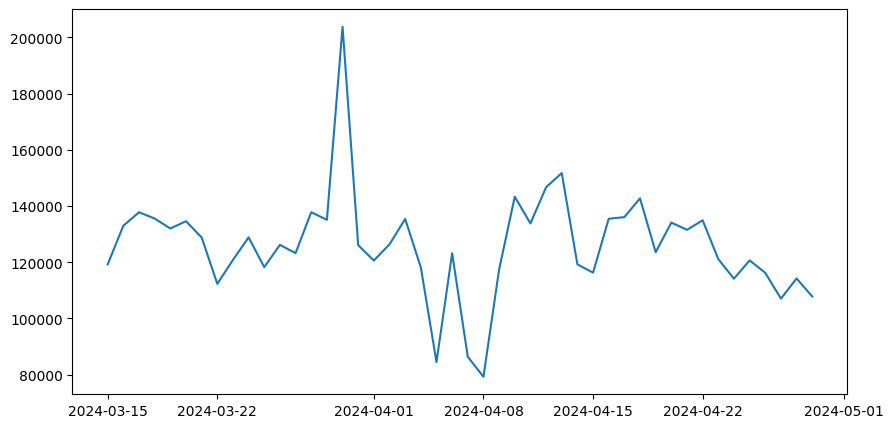

In [90]:
plt.figure(figsize=(10, 5))
plt.plot(pd.DatetimeIndex(dates)[46:], np.count_nonzero(~np.isnan(z_score_base),axis=0)[46:])

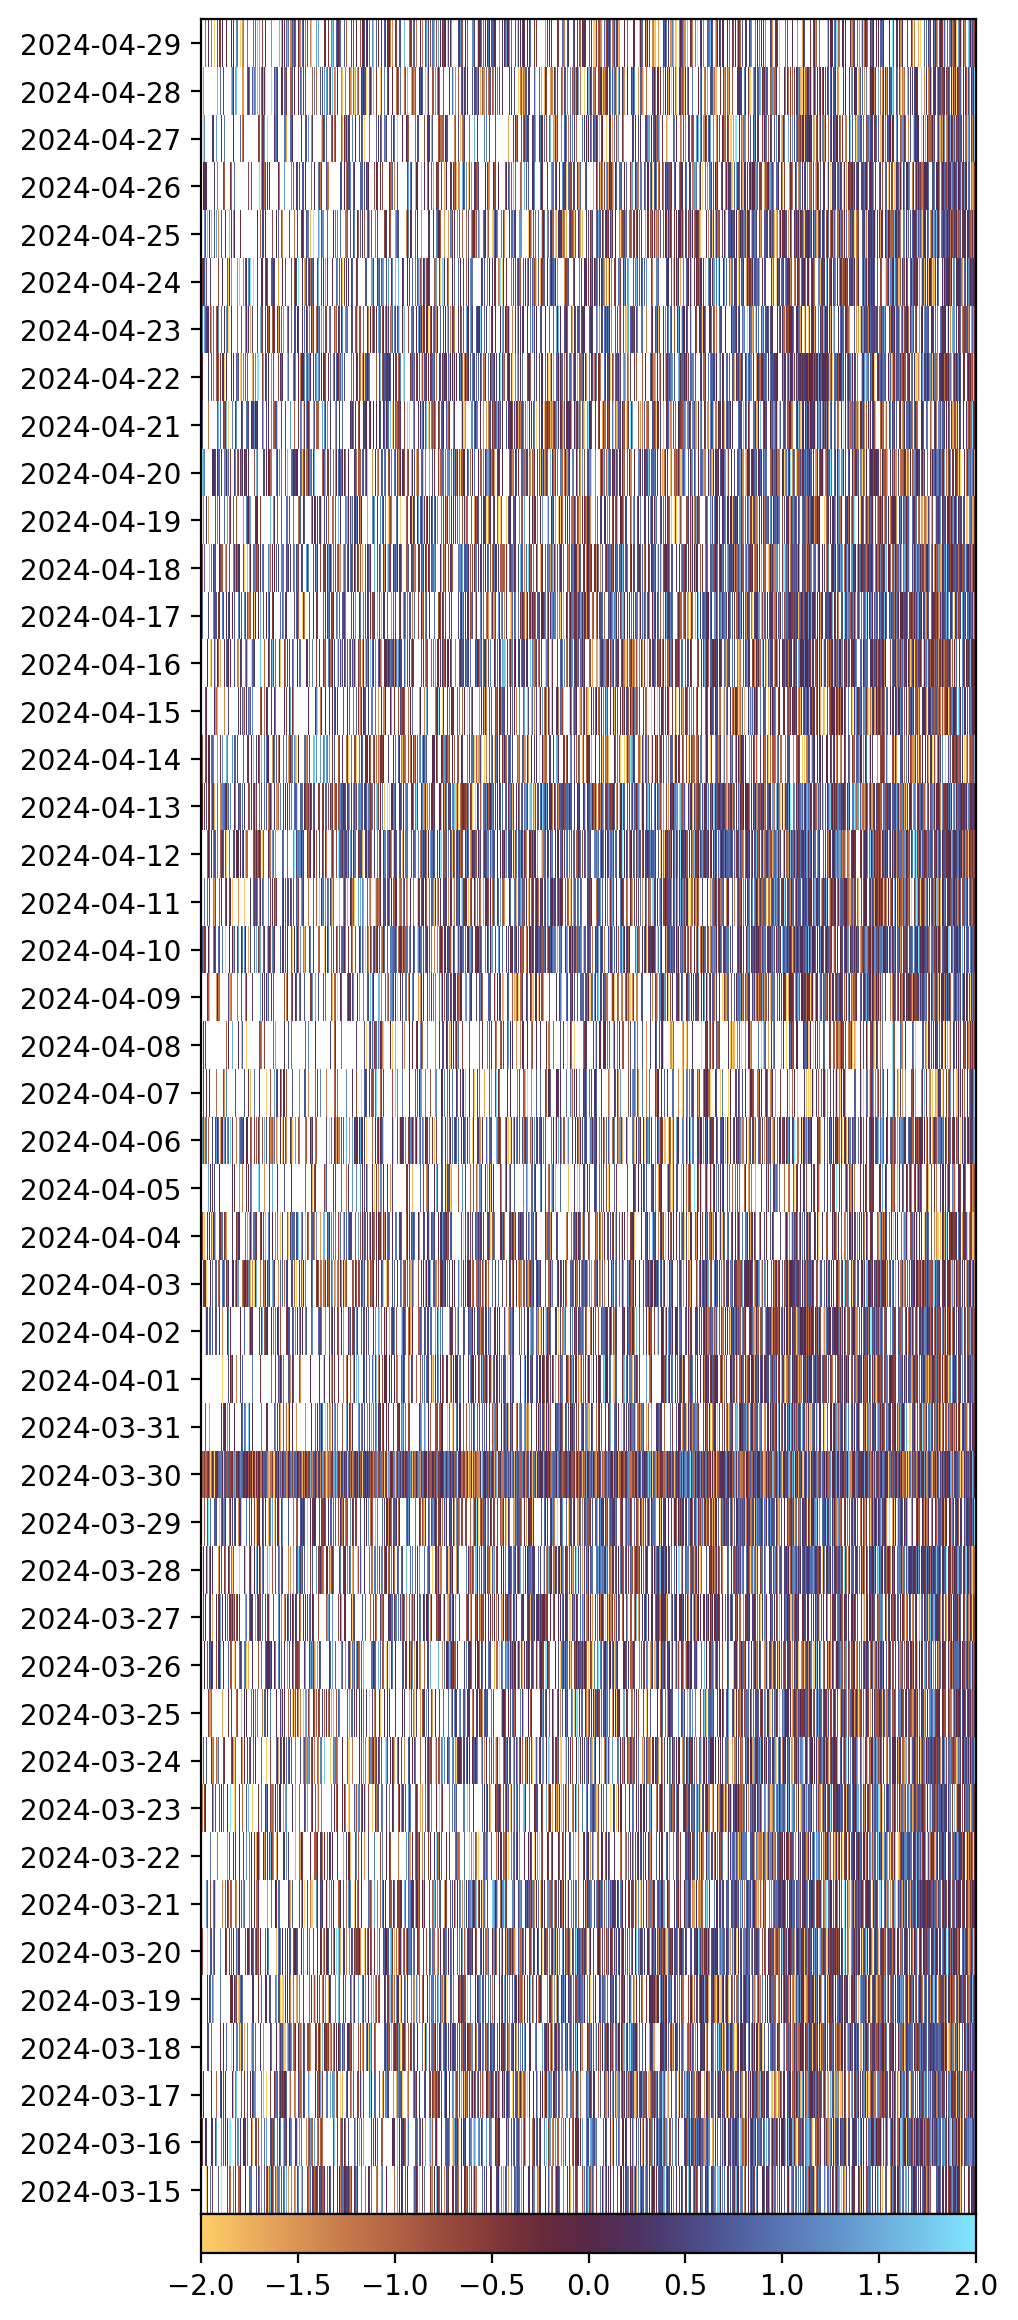

In [112]:
plt.figure(figsize=(5, 15), dpi=200)
plt.pcolormesh(z_score_base.iloc[row_align].T, vmin=-2, vmax=2, cmap="managua")
_ = plt.yticks(np.arange(0.5, z_score_base.shape[1] + 0.5), dates)
plt.xticks([])
plt.colorbar(orientation="horizontal", pad=0, fraction=0.05)
plt.savefig("zscore_uid_dist.png", dpi=300, bbox_inches="tight")

In [47]:
z_score_base

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.440524,-1.193785,-1.356735,0.225841,0.191277,-0.547710,0.567893,0.933231,-1.295951,-1.356735
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.447048,NaN,NaN,-1.399252,0.575874,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-1.821616,-1.821616,NaN,0.597083,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-2.170026,0.034444,0.914514,NaN,0.565580,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.463521,0.623834,0.282542,0.006940,-1.029771,2.530890,0.327722,0.214813,3.149690,-0.402340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.928691,-1.928691,-0.867631,-0.669326,0.654599,0.221539,0.539982,1.252048,0.999220,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.318452,0.665885,0.626638,NaN,NaN,NaN,NaN,-1.788952,0.475185,0.376202
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.273592,NaN,-0.486337,0.587221,-0.700154,-0.343404,NaN,NaN,0.646165,NaN


In [94]:
ks_2samp(z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-23"].dropna(),
          z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-04-06"].dropna())

KstestResult(statistic=np.float64(0.07956613037384053), pvalue=np.float64(1.4116221771832854e-289), statistic_location=np.float64(0.09184194395623618), statistic_sign=np.int8(-1))

In [529]:
z_score_base

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.786118,-7.550158,-8.580745,1.428344,1.209740,-3.464022,3.591673,5.902274,-8.196311,-8.580745
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.719288,NaN,NaN,-8.511316,3.502906,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-12.620528,-12.620528,NaN,4.136714,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-14.229815,0.225861,5.996869,NaN,3.708756,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.967983,3.994486,1.809149,0.044440,-6.593751,16.205605,2.098445,1.375474,20.167855,-2.576232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-11.889247,-11.889247,-5.348439,-4.126003,4.035217,1.365660,3.328671,7.718140,6.159603,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.127484,4.104792,3.862859,NaN,NaN,NaN,NaN,-11.027839,2.929239,2.319063
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.708584,NaN,-3.037176,3.667193,-4.372461,-2.144560,NaN,NaN,4.035299,NaN


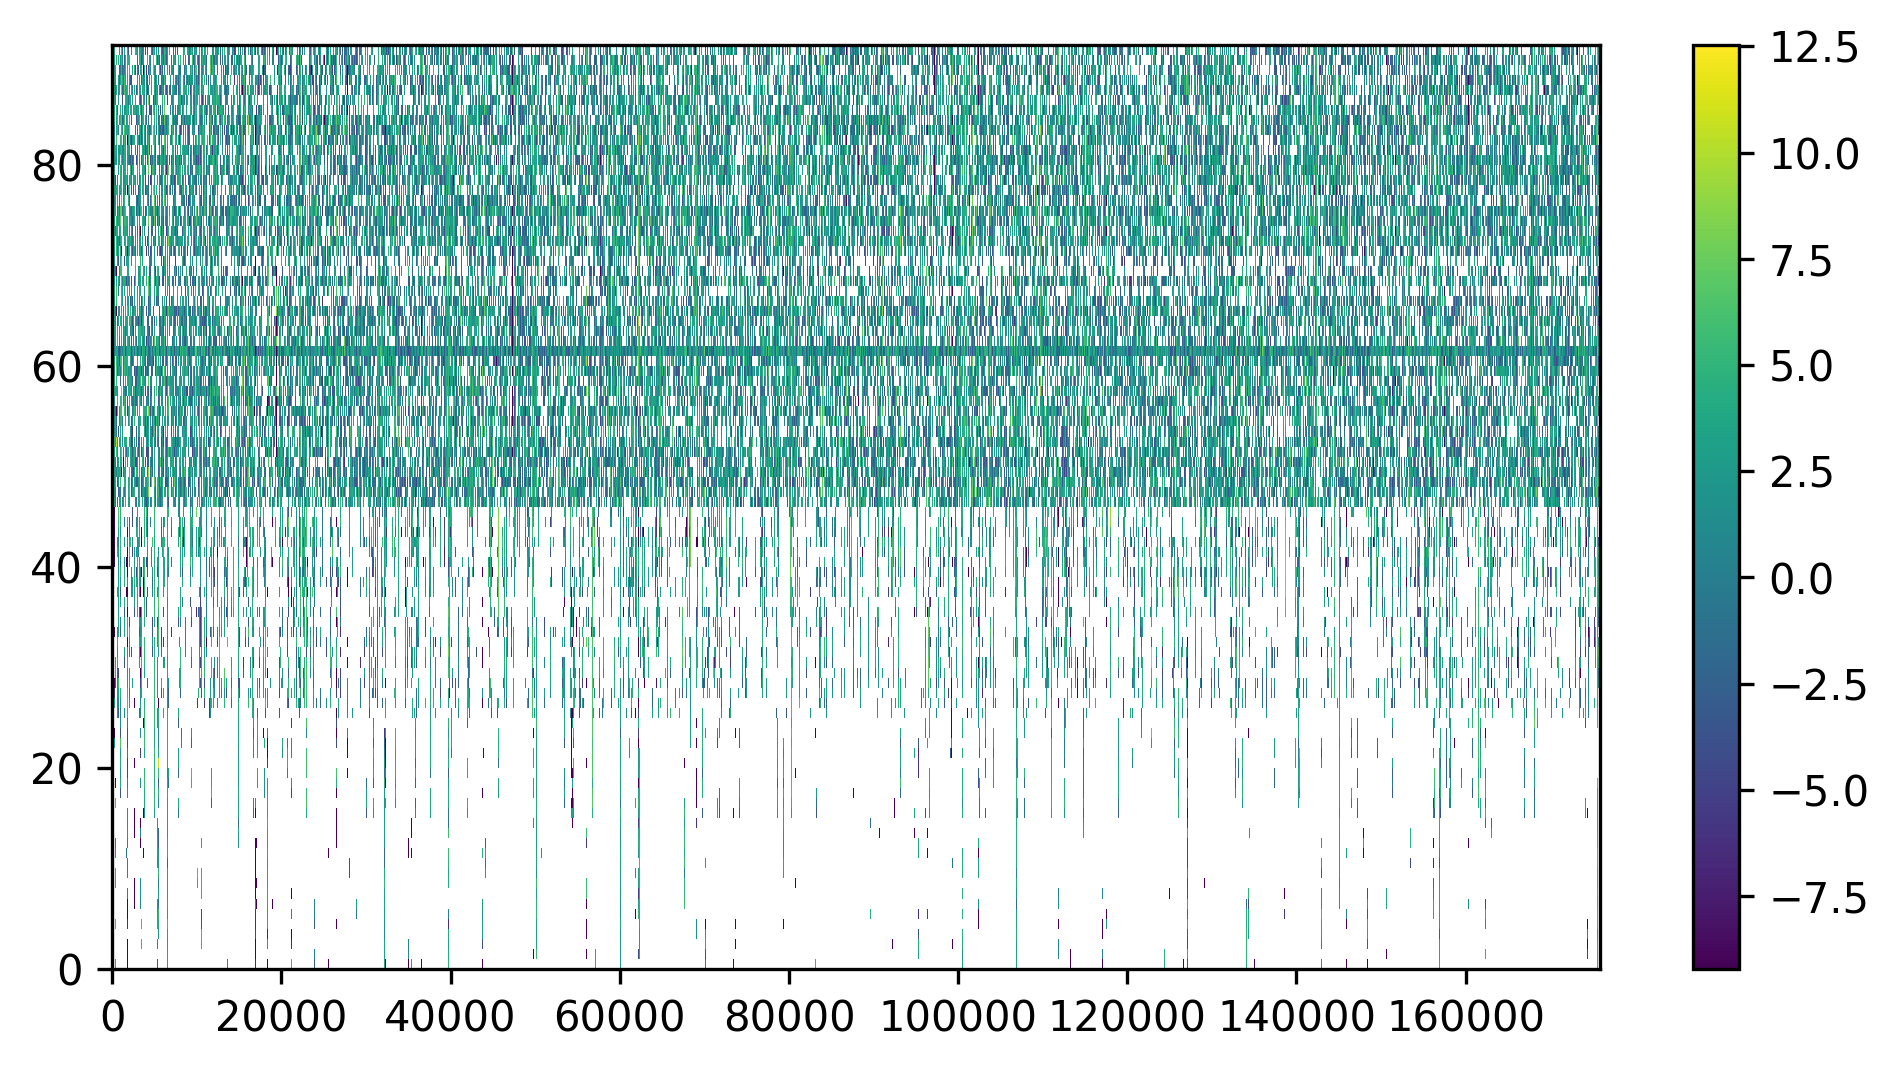

In [95]:
plt.figure(figsize=(8, 4), dpi=300)
plt.pcolormesh(base_log_metric[daily_ar_data_sub["county"] == "LA"].T)
plt.colorbar()

In [407]:
base_log_metric.columns[46:]

Index(['distance_straight_line_2024-03-15',
       'distance_straight_line_2024-03-16',
       'distance_straight_line_2024-03-17',
       'distance_straight_line_2024-03-18',
       'distance_straight_line_2024-03-19',
       'distance_straight_line_2024-03-20',
       'distance_straight_line_2024-03-21',
       'distance_straight_line_2024-03-22',
       'distance_straight_line_2024-03-23',
       'distance_straight_line_2024-03-24',
       'distance_straight_line_2024-03-25',
       'distance_straight_line_2024-03-26',
       'distance_straight_line_2024-03-27',
       'distance_straight_line_2024-03-28',
       'distance_straight_line_2024-04-02',
       'distance_straight_line_2024-04-03',
       'distance_straight_line_2024-04-04',
       'distance_straight_line_2024-04-05',
       'distance_straight_line_2024-04-06',
       'distance_straight_line_2024-04-07',
       'distance_straight_line_2024-04-08',
       'distance_straight_line_2024-04-09',
       'distance_straight_line_2

In [185]:
m_date = "2024-03-30"
m_col = f"{metric}_{m_date}"
good_vals = np.count_nonzero(~np.isnan(df_joined[baseline_cols.values]), axis=1)
metric_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1)[m_col] - 1) / good_vals)
all_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1) - 1) / good_vals.reshape(-1, 1))


In [183]:
metric_quantiles

uid
0000292d773980cdf3926d34b3275e95a56d5e31e3c90fdb9e70a25cfcd8750f    0.793103
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99    0.944444
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4    0.222222
000113ce3330cb882b58599914da21cdc3f0519a1c23811ef47349987eee7a26    0.178571
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4    0.473684
                                                                      ...   
fffeff7aa60ecfde112609f32fcee989a8b134379f255ac35b015803216ad4c0    0.888889
fffeffd69e034688698f5e1537cc707055798167994b71f0d9c29b10e6145d17    0.909091
ffff0966698509c8a2ca9ebb8749a197592f6389bbe71ebaa73240edcbf30060    0.320000
ffff52e9005912d53fd42be3347e917540ccb8ad1ca3764f0b441b483c837def    0.000000
ffff8c6eca66e179685ada7106011ec94a8e64faf7aa0fe83cbf978fa6972c13    0.842105
Name: distance_straight_line_2024-03-30, Length: 203797, dtype: float64

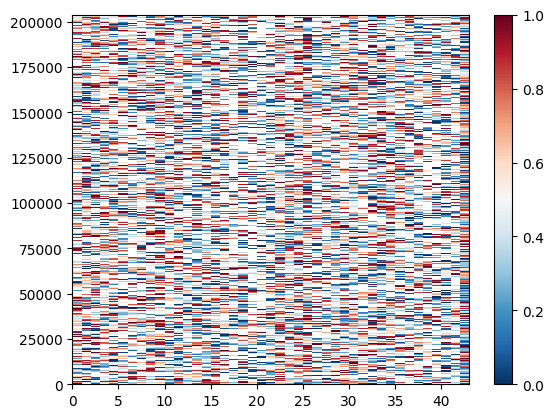

In [186]:
plt.pcolormesh(all_quantiles, cmap="RdBu_r")
plt.colorbar()

In [191]:
np.count_nonzero(metric_quantiles == 1)

9217

In [306]:
np.nanmax(df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1).values)

np.float64(89.0)

In [308]:
good_vals.min()

np.int64(28)

In [114]:
user_home_meta[m_col] = metric_quantiles

In [117]:
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
daily_ar_data_sub = daily_ar_data.loc[user_home_meta.index]

county
LA    Axes(0.125,0.11;0.775x0.77)
SB    Axes(0.125,0.11;0.775x0.77)
VE    Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

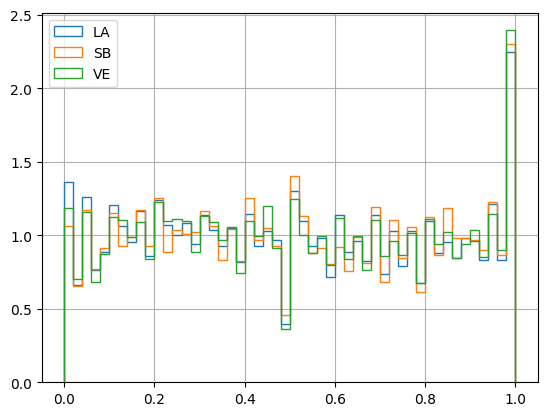

In [180]:
user_home_meta.groupby("county")[m_col].hist(bins=50, 
                                            histtype="step", density=True, 
                                            legend=True)


In [116]:
ar_mrms_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_*.parquet"))

In [187]:
ar_mrms_files

['/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-27_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-28_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-29_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-30_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-31_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-04-01_PST_chunked.parquet']

<Axes: >

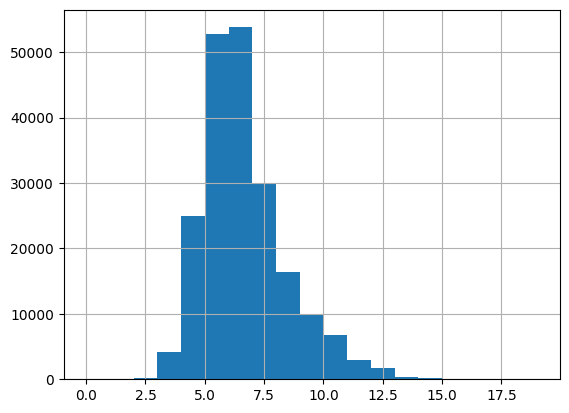

In [121]:
daily_ar_data_sub["precip_max"].hist(bins=np.arange(0, 20))
#plt.gca().set_yscale('log')

In [317]:
daily_ar_data_sub.columns

Index(['duration', 'lat_home', 'lng_home', 'zipcode', 'row_group', 'county',
       'number_of_visits', 'distance_straight_line', 'jump_lengths',
       'radius_of_gyration', 'num_stops', 'max_distance_from_home', 'date',
       'FFW', 'precip_max', 'precip_sum', 'streamflow_max', 'streamflow_sum',
       'distance_straight_line_2024-03-30', 'streamflow_max_flag',
       'precip_sum_flag', 'precip_max_flag'],
      dtype='object')

In [170]:
daily_ar_data_sub[m_col] = metric_quantiles
daily_ar_data_sub["streamflow_max_flag"] = daily_ar_data_sub["streamflow_max"] >= 1.1
daily_ar_data_sub["precip_max_flag"] = daily_ar_data_sub["precip_max"] >= 6.4

In [171]:
daily_ar_data_sub.groupby("streamflow_max_flag").count()

,duration,lat_home,lng_home,zipcode,row_group,county,number_of_visits,distance_straight_line,jump_lengths,radius_of_gyration,num_stops,max_distance_from_home,date,FFW,precip_max,precip_sum,streamflow_max,streamflow_sum,distance_straight_line_2024-03-30,precip_max_flag
streamflow_max_flag,,,,,,,,,,,,,,,,,,,,
False,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123,110123
True,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674,93674


precip_max_flag
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

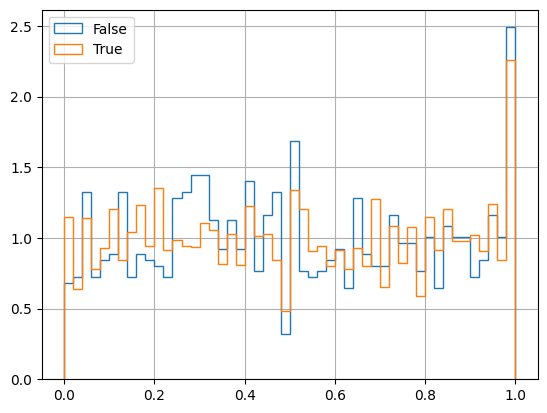

In [158]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "SB"].groupby("precip_max_flag")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=False)


In [154]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "LA")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "LA")])

KstestResult(statistic=np.float64(0.009901526357842583), pvalue=np.float64(0.0003797345770280587), statistic_location=np.float64(0.6153846153846154), statistic_sign=np.int8(-1))

In [155]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.009488710547647217), pvalue=np.float64(0.7971219749434347), statistic_location=np.float64(0.7916666666666666), statistic_sign=np.int8(-1))

In [156]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "SB")], 
         metric_quantiles[(~daily_ar_data_sub["precip_max_flag"]) & (daily_ar_data_sub["county"] == "SB")])

KstestResult(statistic=np.float64(0.034901514051452795), pvalue=np.float64(0.1590862141287467), statistic_location=np.float64(0.23333333333333334), statistic_sign=np.int8(1))

streamflow_max_flag
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

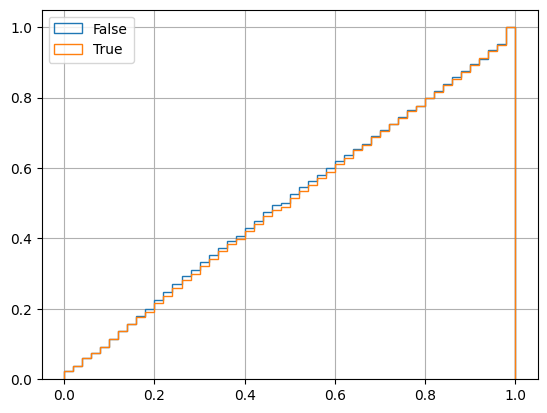

In [175]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "VE"].groupby("streamflow_max_flag")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=True)


In [178]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["streamflow_max_flag"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["streamflow_max_flag"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.013740544191791992), pvalue=np.float64(0.3034727827363506), statistic_location=np.float64(0.4634146341463415), statistic_sign=np.int8(-1))

FFW
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

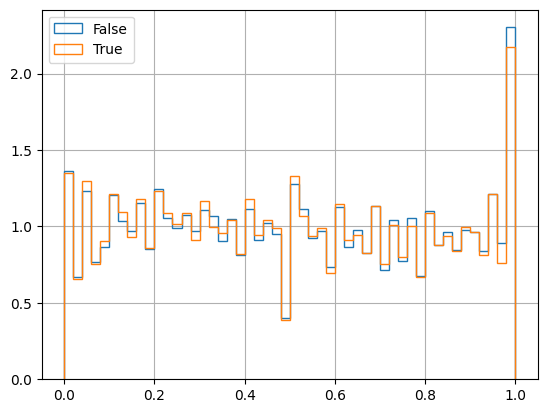

In [134]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "LA"].groupby("FFW")[m_col].hist(bins=50, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=False)

In [127]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")])

KstestResult(statistic=np.float64(0.007652804065844454), pvalue=np.float64(0.012074331416729716), statistic_location=np.float64(0.6410256410256411), statistic_sign=np.int8(1))

In [128]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")])

KstestResult(statistic=np.float64(0.04764445411348328), pvalue=np.float64(0.37049701432587934), statistic_location=np.float64(0.7037037037037037), statistic_sign=np.int8(1))

In [129]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "SB")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "SB")])

KstestResult(statistic=np.float64(0.015431707676440254), pvalue=np.float64(0.8545535143443042), statistic_location=np.float64(0.21875), statistic_sign=np.int8(-1))

<Axes: >

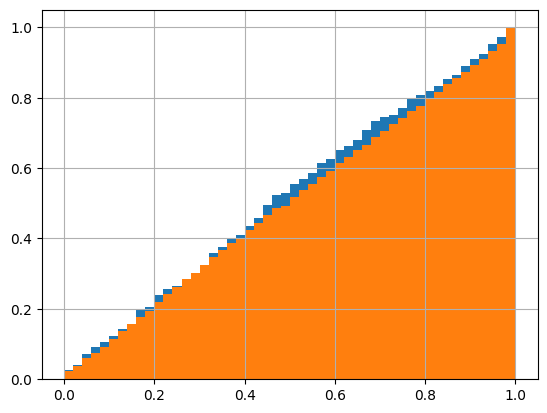

In [135]:
metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True,cumulative=True, bins=50)
metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True, cumulative=True, bins=50)